<a href="https://www.kaggle.com/code/lalit7881/diabetes-eda-100?scriptVersionId=358303757" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")
# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/datascikhan/diabetes/diabetes_large_dataset.csv


## Loading dataset

In [2]:
df = pd.read_csv("/kaggle/input/datasets/datascikhan/diabetes/diabetes_large_dataset.csv")

In [3]:
df.head()

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
0,P000001,R00000001,57.0,51-60,Male,Male,Black,Black,Married,Some College,...,2.4,86.8,86.0,64.7,89.4,1,2,0,NaN,No Diabetes
1,P000002,R00000002,47.0,41-50,Female,Female,White,White,Married,High School,...,2.7,85.5,86.2,78.4,80.0,3,0,0,NaN,No Diabetes
2,P000003,R00000003,59.0,51-60,Male,Male,Black,Black,Married,Some College,...,19.3,66.0,66.1,56.7,64.7,2,0,1,1.0,Type 2
3,P000004,R00000004,72.0,71-90,Female,Female,Black,Black,Single,Master,...,0.9,61.8,64.4,68.6,59.6,3,0,0,0.0,No Diabetes
4,P000005,R00000005,46.0,41-50,Male,Male,Hispanic,Hispanic,Married,Bachelor,...,6.3,80.4,81.8,73.0,76.7,1,0,2,0.0,No Diabetes


In [4]:
df.tail()

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
99995,P099996,R00099996,46.0,41-50,Male,Male,Black,Black,Divorced,Bachelor,...,0.3,73.2,69.2,53.4,58.2,2,0,1,0.0,No Diabetes
99996,P099997,R00099997,41.0,41-50,Female,Female,Asian,Asian,Married,Some College,...,4.0,77.6,77.4,77.6,86.3,4,2,0,0.0,No Diabetes
99997,P099998,R00099998,56.0,51-60,Female,Female,White,White,Widowed,High School,...,0.0,94.0,96.4,58.7,83.4,0,1,0,0.0,No Diabetes
99998,P099999,R00099999,46.0,41-50,Female,Female,White,White,Married,Bachelor,...,7.6,64.9,67.2,55.8,60.5,4,3,0,0.0,No Diabetes
99999,P100000,R00100000,51.0,51-60,Female,Female,Native American,Native American,Married,High School,...,0.0,80.9,71.0,82.9,84.9,4,2,0,0.0,No Diabetes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Columns: 209 entries, patient_id to diabetes_type
dtypes: float64(102), int64(15), object(92)
memory usage: 159.5+ MB


In [6]:
df.describe()

,age,annual_income,household_size,dependents,height_cm,weight_kg,bmi,waist_circumference_cm,hip_circumference_cm,waist_to_hip_ratio,...,obesity_risk_score,hypertension_risk_score,kidney_risk_score,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,diabetes_status
count,98007.000000,100000.000000,100000.000000,100000.000000,95043.000000,95071.000000,97978.000000,94880.000000,94997.000000,100000.000000,...,100000.000000,100000.000000,100000.000000,98035.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,97980.000000
mean,49.599100,61622.162979,3.217860,1.784010,168.337098,79.191255,28.037369,85.320099,102.100620,0.836912,...,24.067593,33.375916,16.806100,11.263883,73.415337,73.377483,65.487039,72.499750,2.533050,0.279720
std,14.733998,42453.523065,1.678894,1.625154,9.397740,16.529756,5.945927,12.741135,10.517227,0.100990,...,20.708542,18.658692,14.152643,15.227705,12.604604,13.449474,12.570501,10.934267,1.770158,0.448864
min,18.000000,10000.000000,1.000000,0.000000,140.000000,35.000000,9.940000,50.000000,61.900000,0.493000,...,0.000000,0.000000,0.000000,0.000000,12.100000,5.000000,9.700000,22.800000,0.000000,0.000000
25%,39.000000,30194.305000,2.000000,0.000000,161.400000,67.900000,23.950000,76.700000,94.900000,0.763000,...,5.300000,19.900000,4.500000,0.900000,65.200000,64.500000,57.300000,65.200000,1.000000,0.000000
50%,50.000000,51370.585000,3.000000,2.000000,168.000000,79.000000,27.880000,85.200000,101.800000,0.836000,...,21.300000,33.200000,14.500000,6.300000,74.400000,74.200000,66.000000,72.700000,2.000000,0.000000
75%,60.000000,79948.430000,4.000000,3.000000,175.200000,90.300000,31.910000,93.900000,109.000000,0.910000,...,37.700000,46.200000,26.200000,14.800000,82.400000,83.000000,74.100000,80.100000,4.000000,1.000000
max,90.000000,282671.220000,8.000000,6.000000,203.000000,162.400000,59.692509,140.000000,150.700000,1.280000,...,100.000000,100.000000,77.100000,100.000000,100.000000,100.000000,100.000000,100.000000,8.000000,1.000000


In [7]:
df.isnull().sum()

patient_id                    0
record_id                     0
age                        1993
age_group                     0
sex                        2005
                           ... 
chronic_condition_count       0
hospitalization_history       0
emergency_visit_history       0
diabetes_status            2020
diabetes_type               547
Length: 209, dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.columns

Index(['patient_id', 'record_id', 'age', 'age_group', 'sex', 'gender',
       'ethnicity', 'race_group', 'marital_status', 'education_level',
       ...
       'diabetes_risk_score', 'overall_health_score', 'physical_health_score',
       'mental_wellbeing_score', 'quality_of_life_score',
       'chronic_condition_count', 'hospitalization_history',
       'emergency_visit_history', 'diabetes_status', 'diabetes_type'],
      dtype='object', length=209)

In [10]:
df.nunique()

patient_id                 100000
record_id                  100000
age                            73
age_group                       6
sex                             2
                            ...  
chronic_condition_count         9
hospitalization_history         5
emergency_visit_history         5
diabetes_status                 2
diabetes_type                   5
Length: 209, dtype: int64

In [11]:
df.dtypes

patient_id                  object
record_id                   object
age                        float64
age_group                   object
sex                         object
                            ...   
chronic_condition_count      int64
hospitalization_history     object
emergency_visit_history     object
diabetes_status            float64
diabetes_type               object
Length: 209, dtype: object

In [12]:
df.shape

(100000, 209)

## EDA

HEALTHCARE DATASET OVERVIEW
Dataset shape: (100000, 209)
Total rows: 100000
Total columns: 209

First 5 records:


,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
0,P000001,R00000001,57.0,51-60,Male,Male,Black,Black,Married,Some College,...,2.4,86.8,86.0,64.7,89.4,1,2,0,NaN,No Diabetes
1,P000002,R00000002,47.0,41-50,Female,Female,White,White,Married,High School,...,2.7,85.5,86.2,78.4,80.0,3,0,0,NaN,No Diabetes
2,P000003,R00000003,59.0,51-60,Male,Male,Black,Black,Married,Some College,...,19.3,66.0,66.1,56.7,64.7,2,0,1,1.0,Type 2
3,P000004,R00000004,72.0,71-90,Female,Female,Black,Black,Single,Master,...,0.9,61.8,64.4,68.6,59.6,3,0,0,0.0,No Diabetes
4,P000005,R00000005,46.0,41-50,Male,Male,Hispanic,Hispanic,Married,Bachelor,...,6.3,80.4,81.8,73.0,76.7,1,0,2,0.0,No Diabetes



Column names:
['patient_id', 'record_id', 'age', 'age_group', 'sex', 'gender', 'ethnicity', 'race_group', 'marital_status', 'education_level', 'employment_status', 'occupation_category', 'income_level', 'annual_income', 'household_size', 'dependents', 'residential_area_type', 'urban_rural', 'insurance_status', 'height_cm', 'weight_kg', 'bmi', 'bmi_category', 'waist_circumference_cm', 'hip_circumference_cm', 'waist_to_hip_ratio', 'body_fat_percentage', 'lean_body_mass_kg', 'body_surface_area', 'resting_metabolic_rate', 'fasting_glucose_mg_dl', 'random_glucose_mg_dl', 'post_meal_glucose_mg_dl', 'two_hour_glucose_mg_dl', 'glucose_variability', 'hba1c_percent', 'estimated_average_glucose_mg_dl', 'fasting_insulin_uIU_ml', 'c_peptide_ng_ml', 'insulin_resistance_index', 'systolic_bp', 'diastolic_bp', 'pulse_pressure', 'mean_arterial_pressure', 'heart_rate', 'resting_heart_rate', 'hypertension_status', 'total_cholesterol_mg_dl', 'ldl_mg_dl', 'hdl_mg_dl', 'triglycerides_mg_dl', 'vldl_mg_dl', '

,Count
Data Type,
float64,102
object,92
int64,15



Missing values:


,Missing Values
age_at_menopause,82257
fasting_insulin_uIU_ml,10178
self_management_score,10177
urine_albumin_mg_g,10134
medication_adherence_percent,10054
folate_ng_ml,10045
ferritin_ng_ml,10022
vitamin_d_ng_ml,10018
public_transport_access,10003
c_peptide_ng_ml,9948



Numeric columns: 117
Categorical columns: 92
Identifier columns: ['patient_id', 'record_id']
Age columns: ['age', 'body_fat_percentage', 'estimated_average_glucose_mg_dl', 'self_management_score', 'age_at_menopause']
Diabetes columns: ['family_history_diabetes', 'father_diabetes', 'mother_diabetes', 'sibling_diabetes', 'prediabetes_history', 'gestational_diabetes_history', 'previous_diabetes_diagnosis', 'diabetes_medication', 'diabetes_education_received', 'diabetes_complication_count', 'diabetes_risk_score', 'diabetes_status', 'diabetes_type']
Health score columns: ['environmental_risk_score', 'cardiovascular_risk_score', 'metabolic_risk_score', 'obesity_risk_score', 'hypertension_risk_score', 'kidney_risk_score', 'diabetes_risk_score', 'overall_health_score', 'physical_health_score', 'mental_wellbeing_score', 'quality_of_life_score']


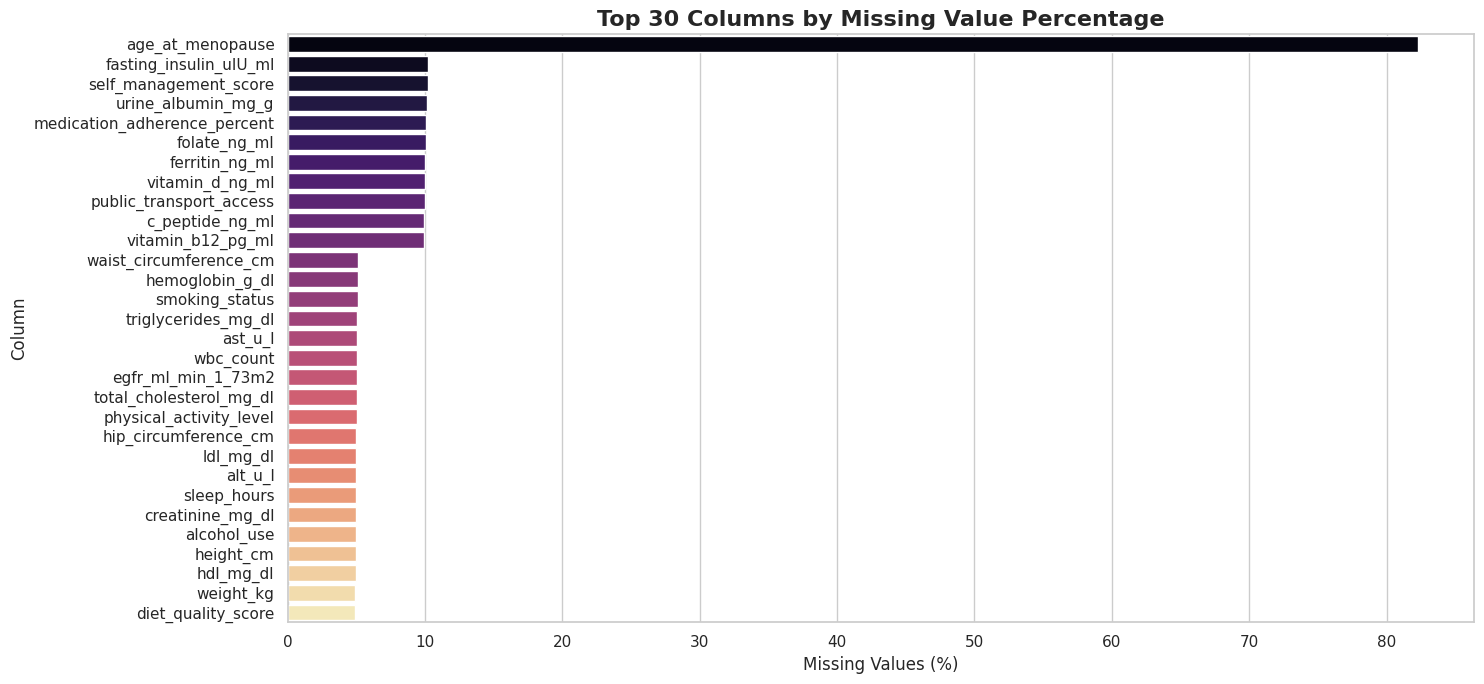

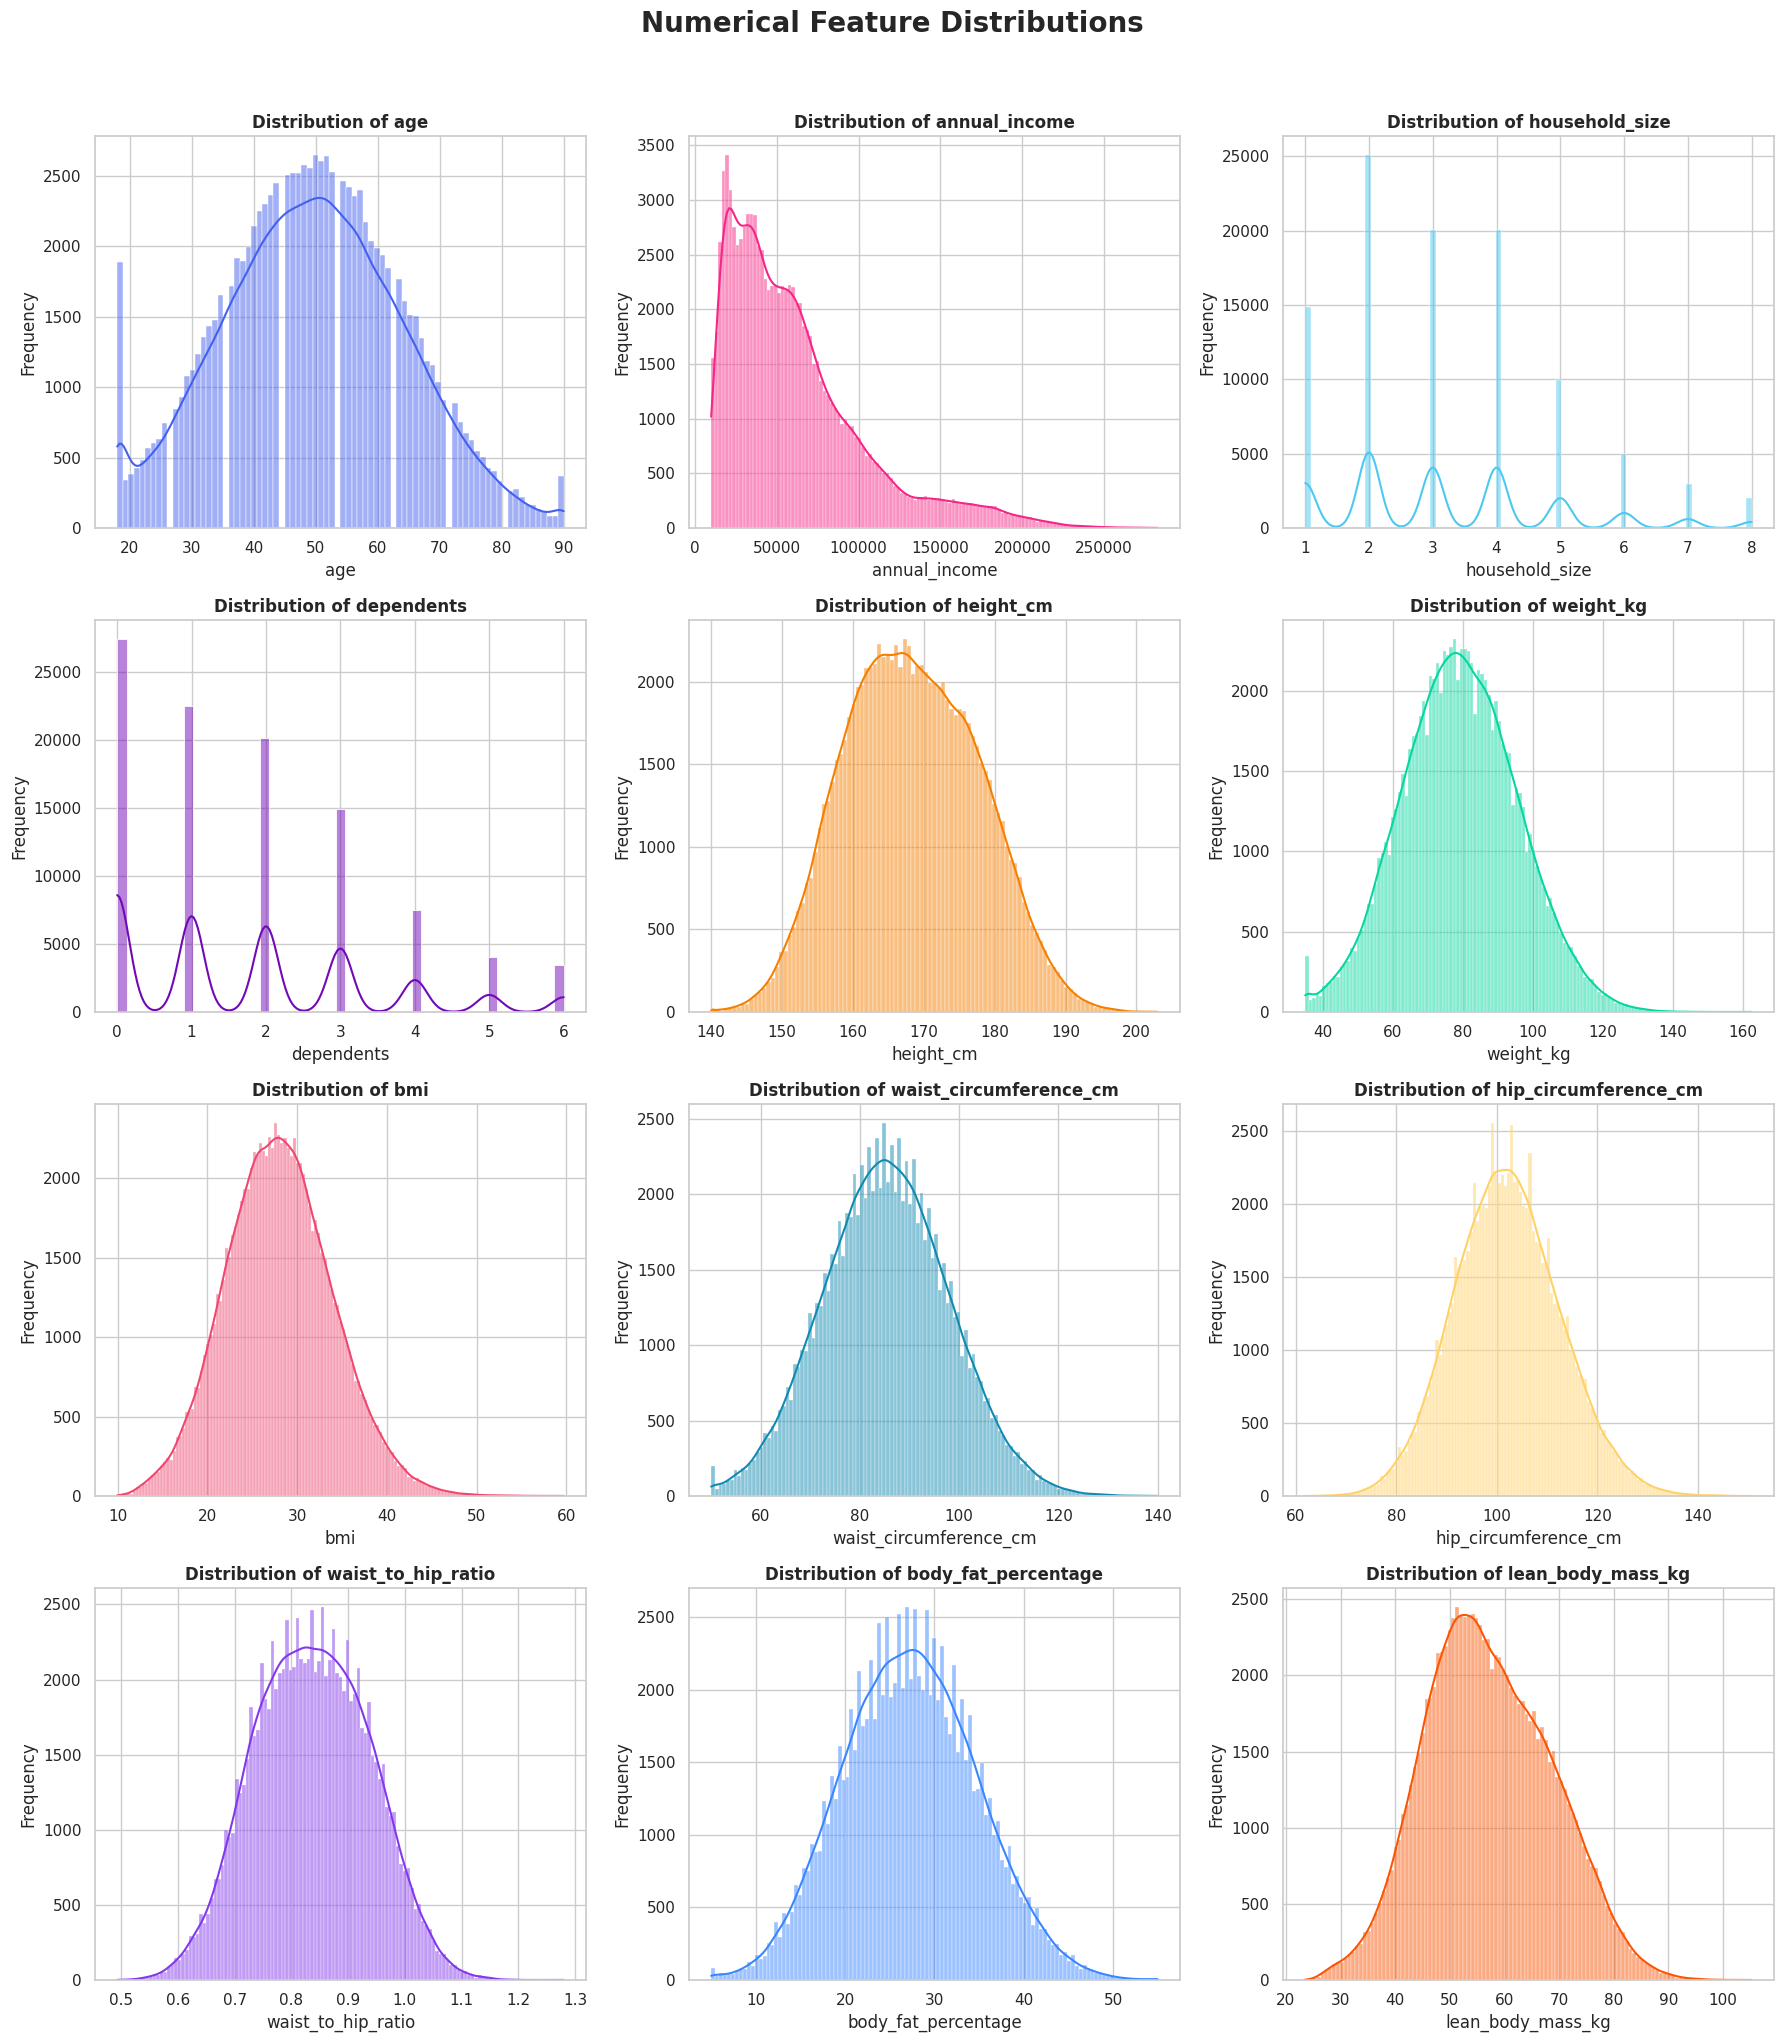

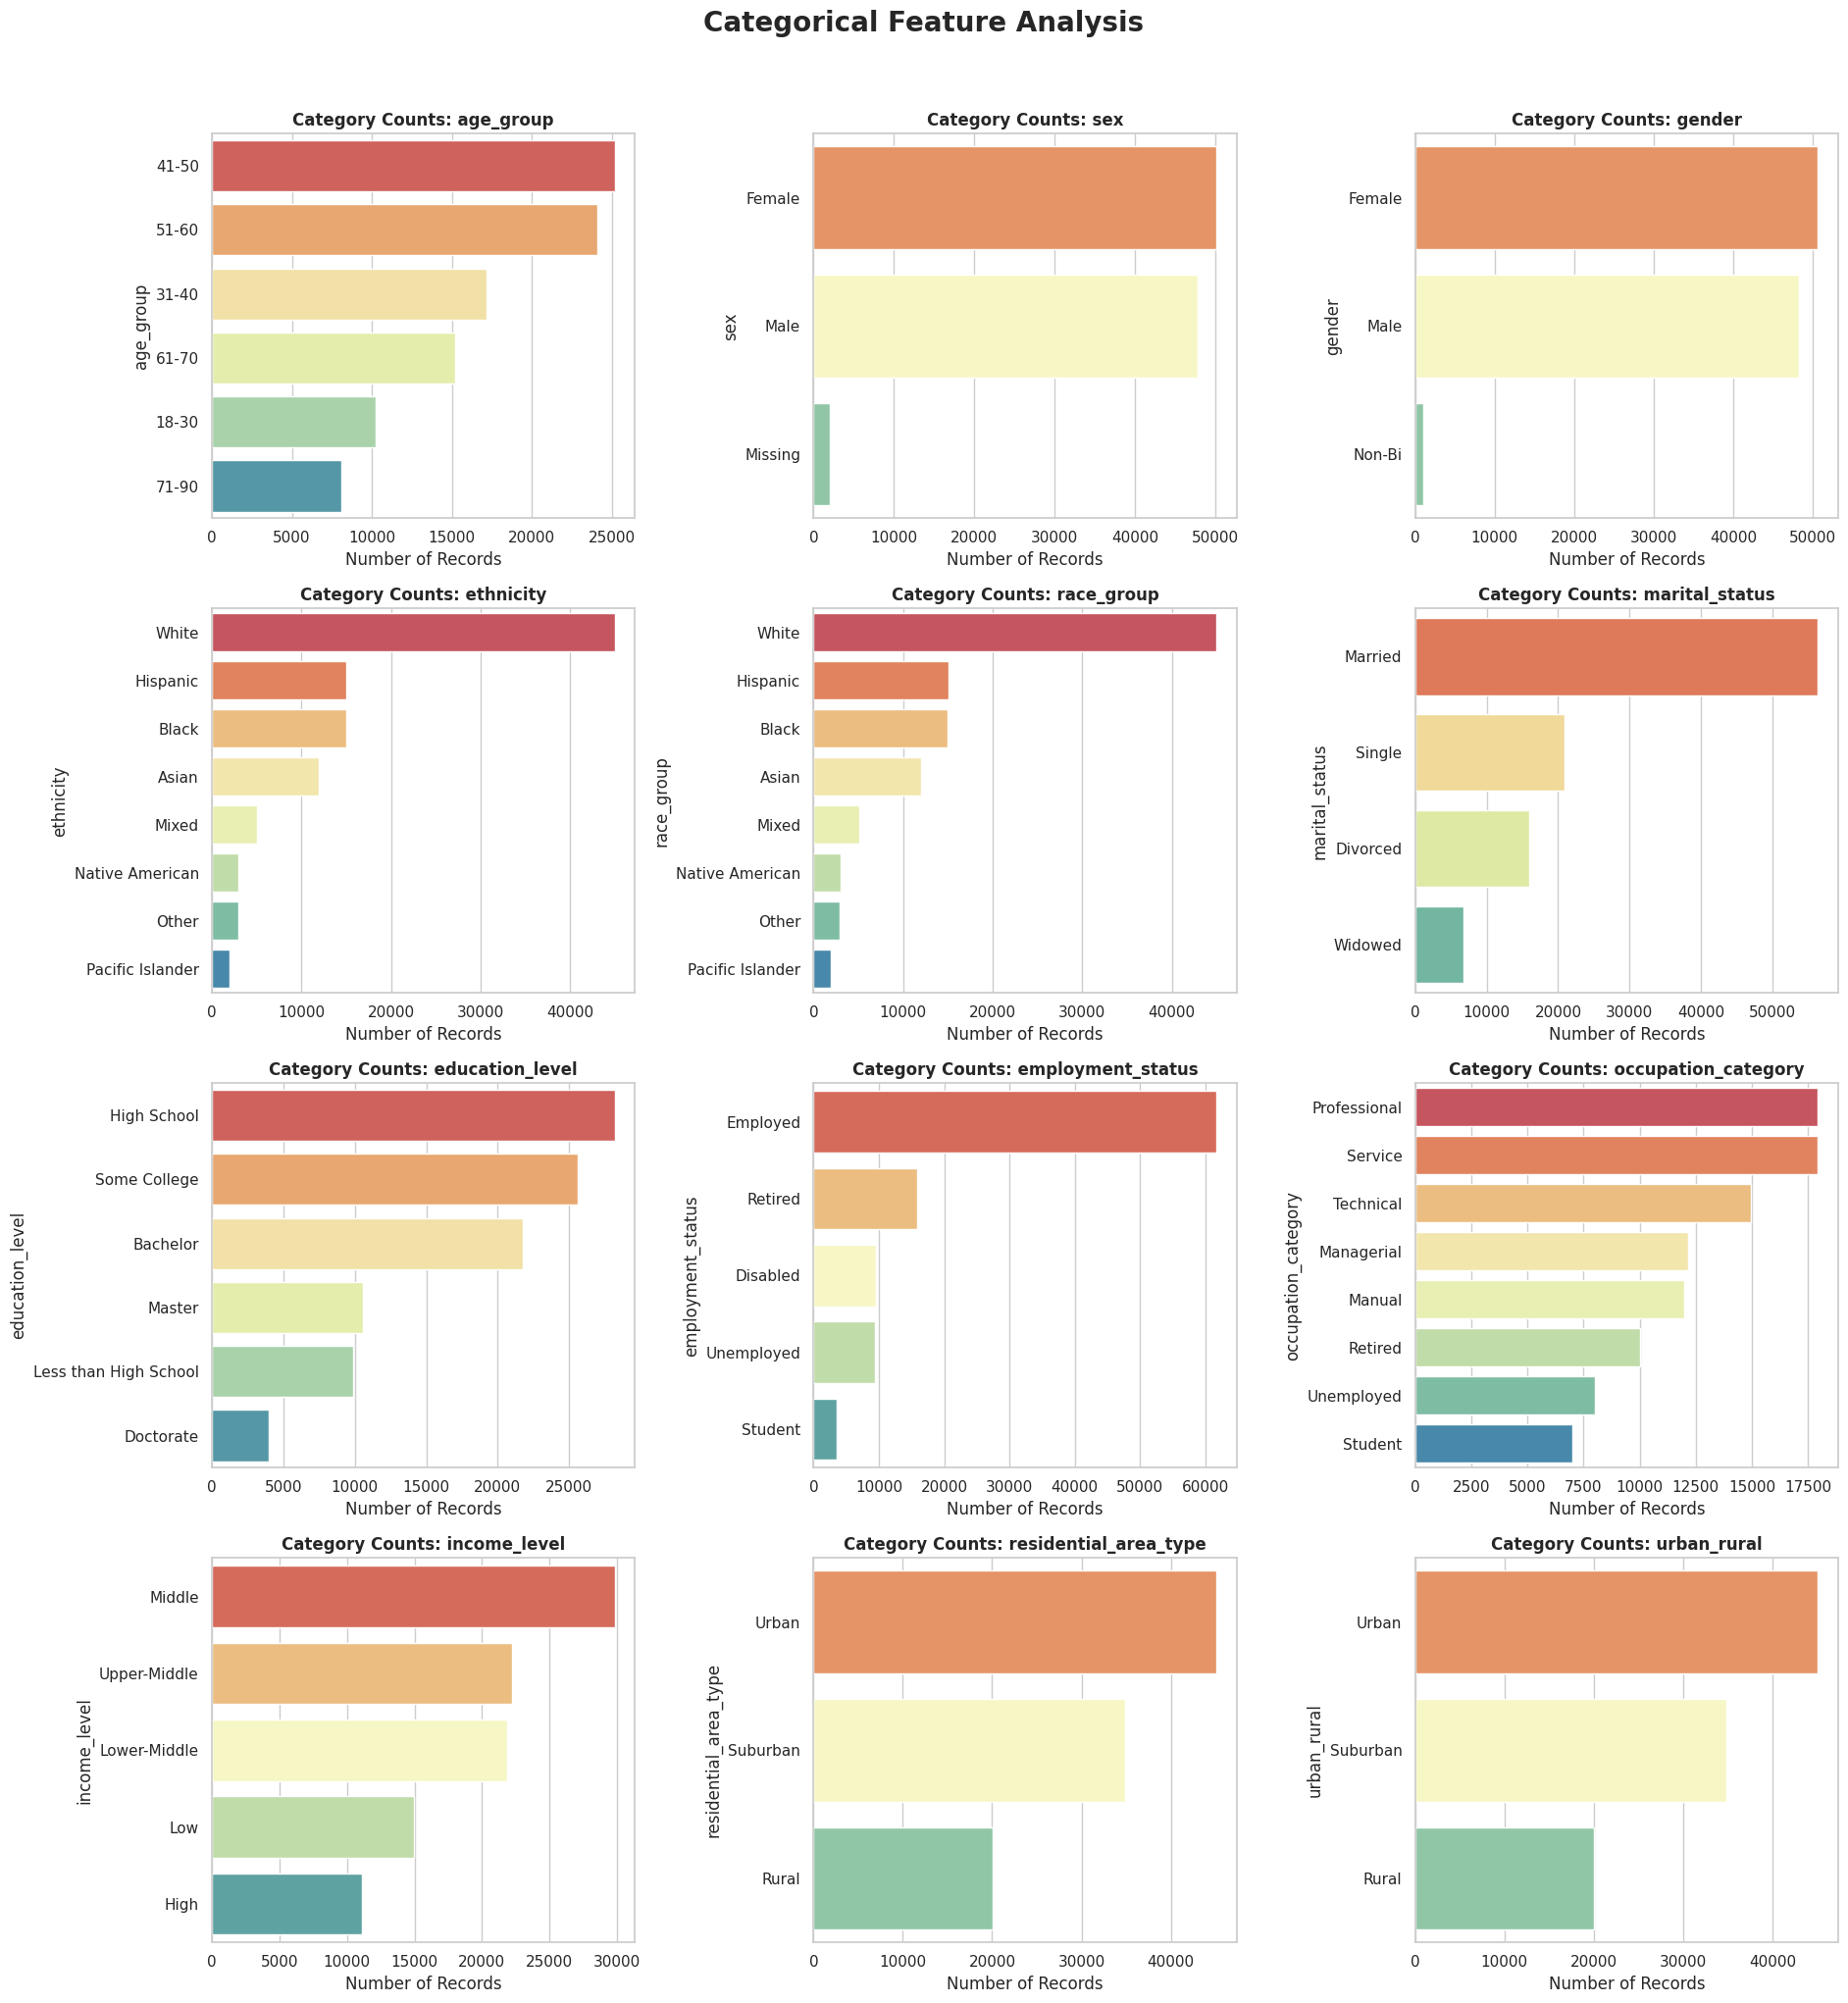

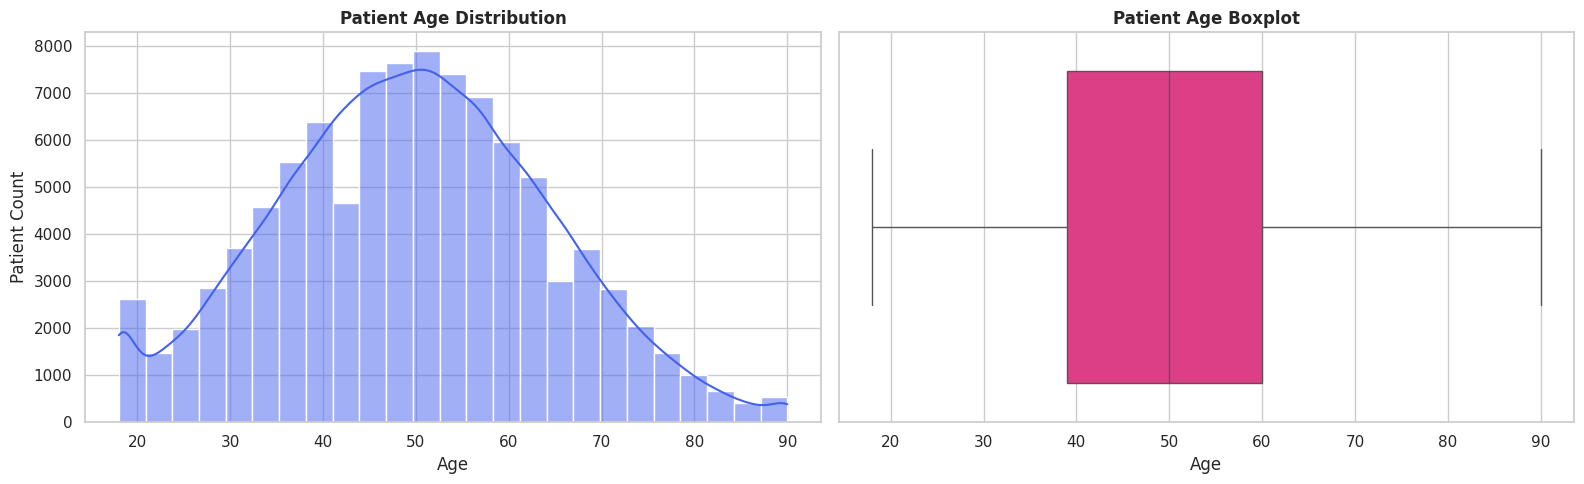

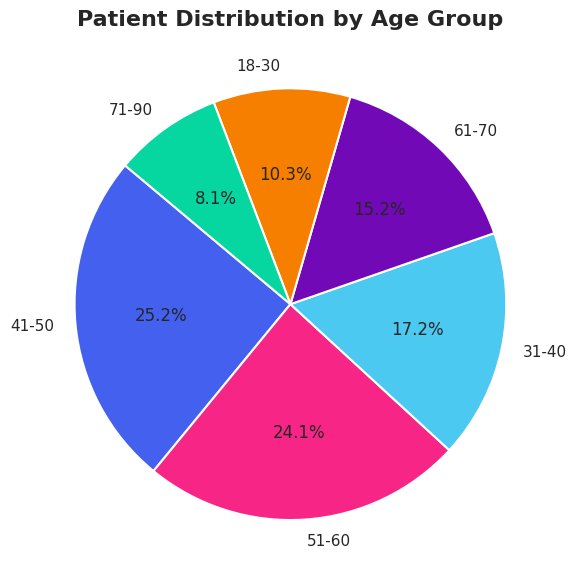

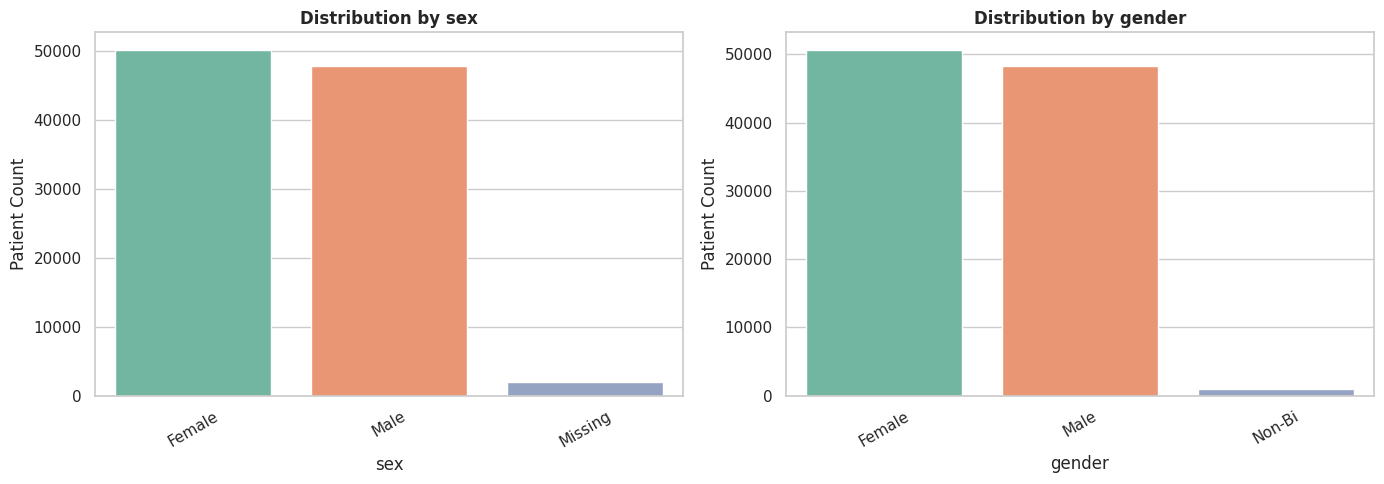

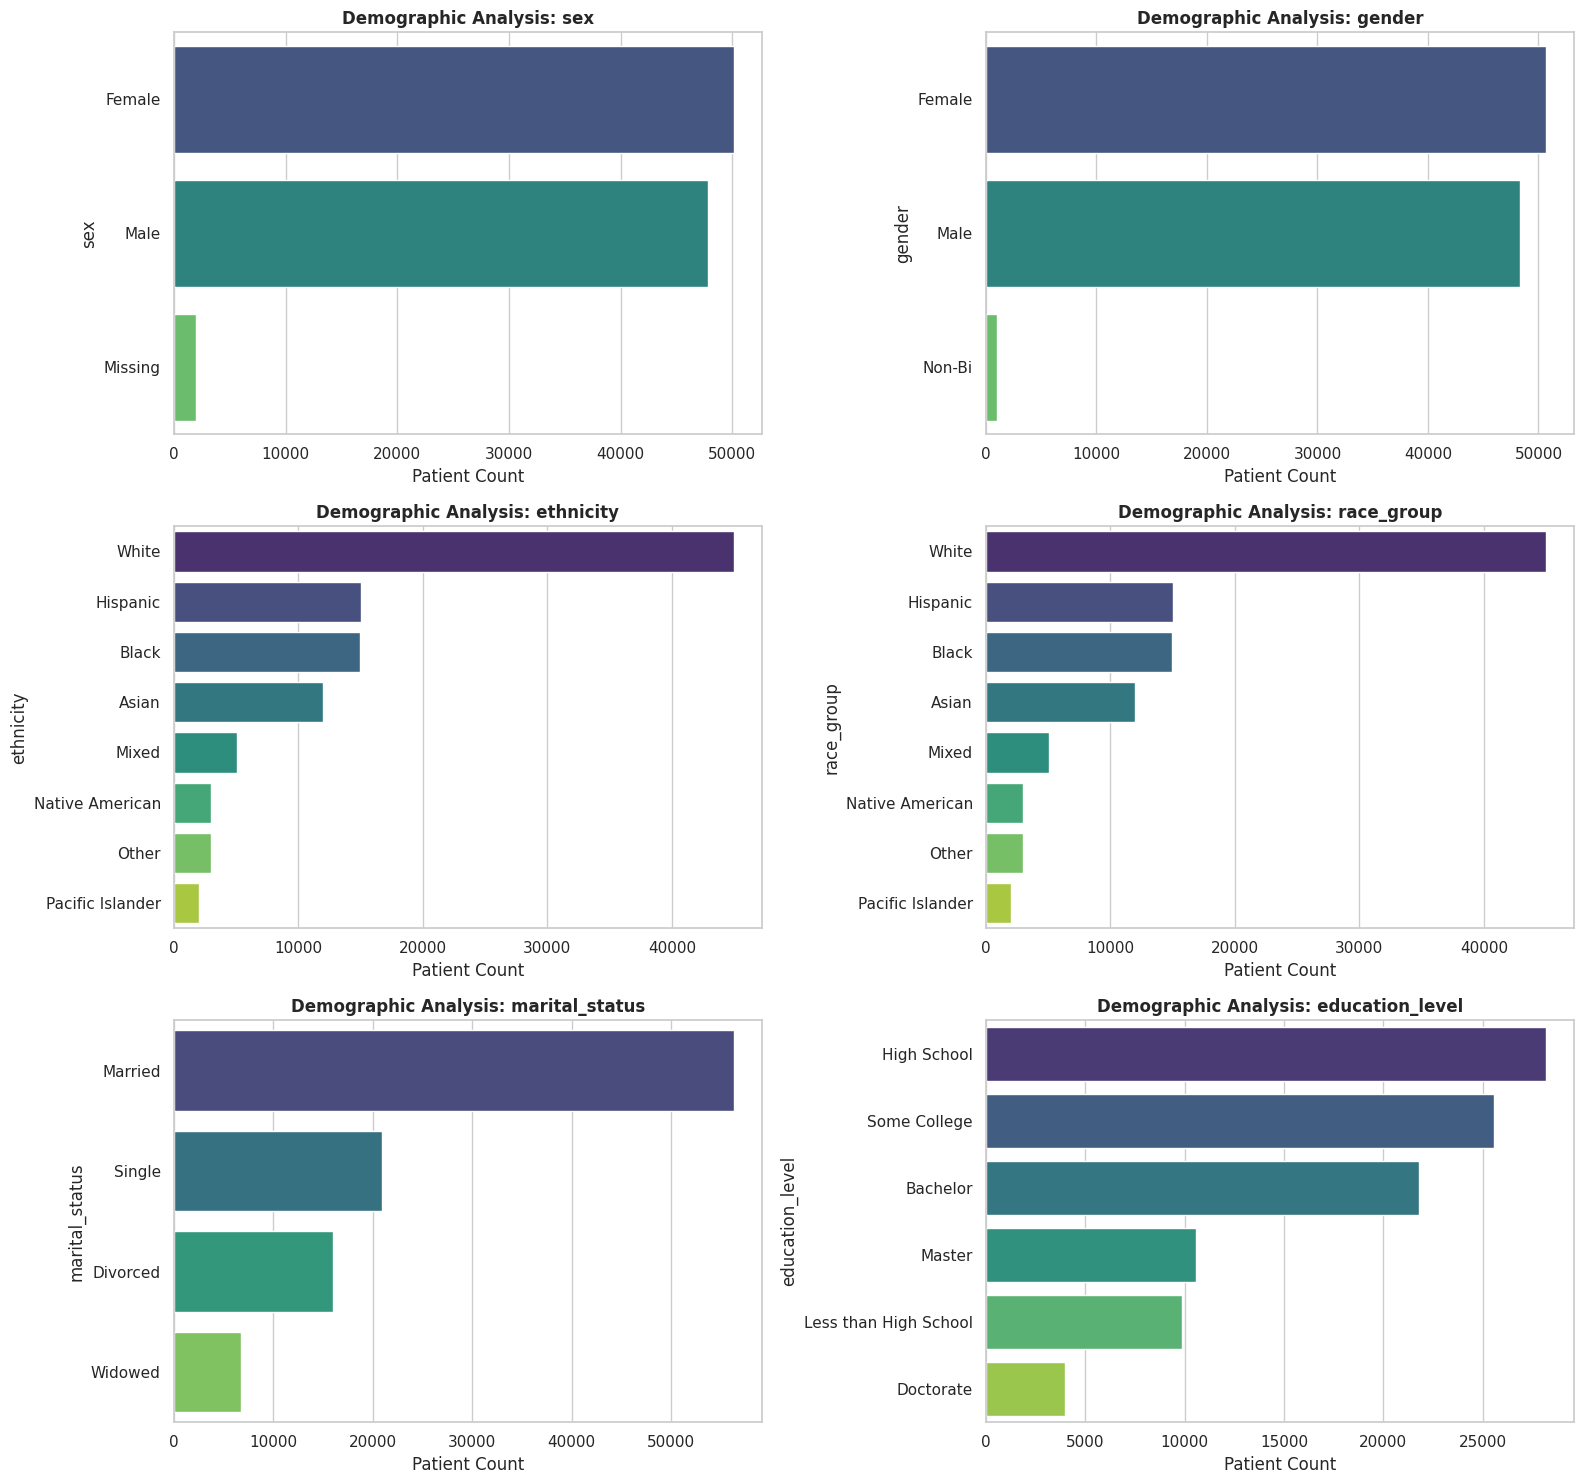

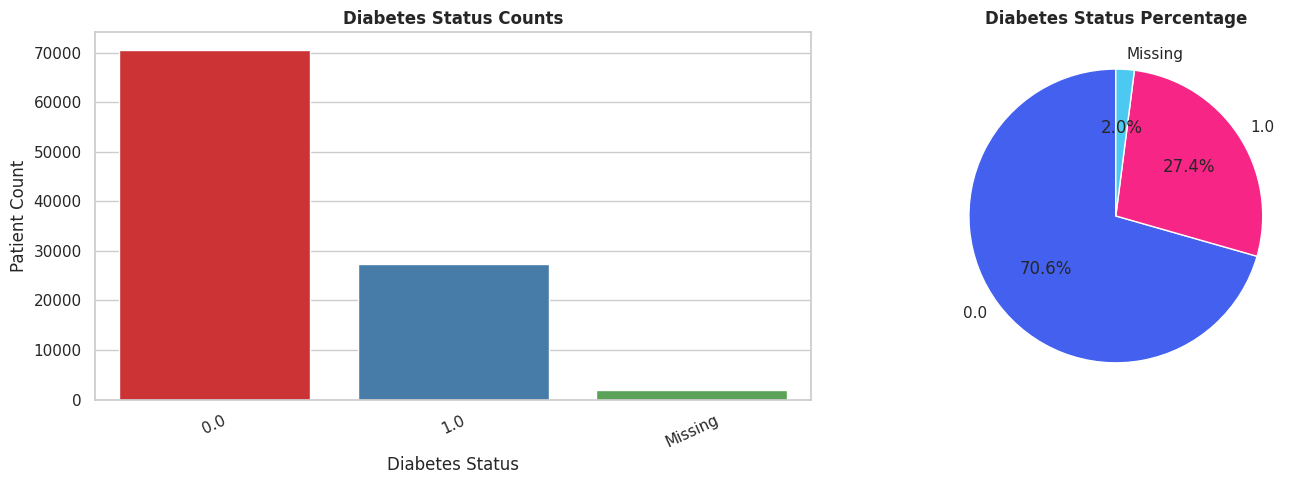

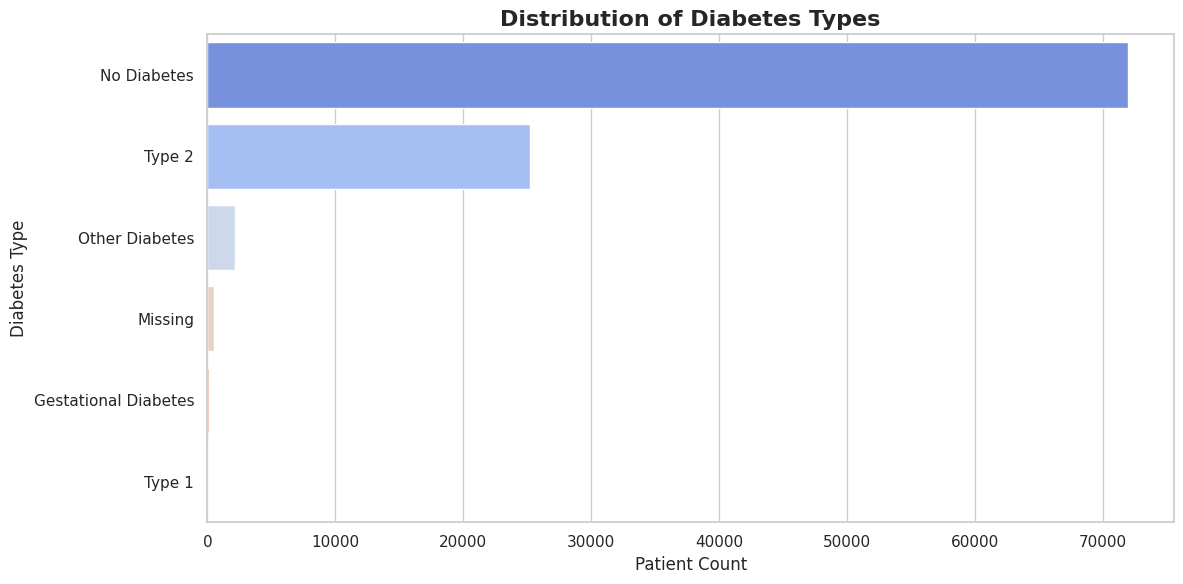

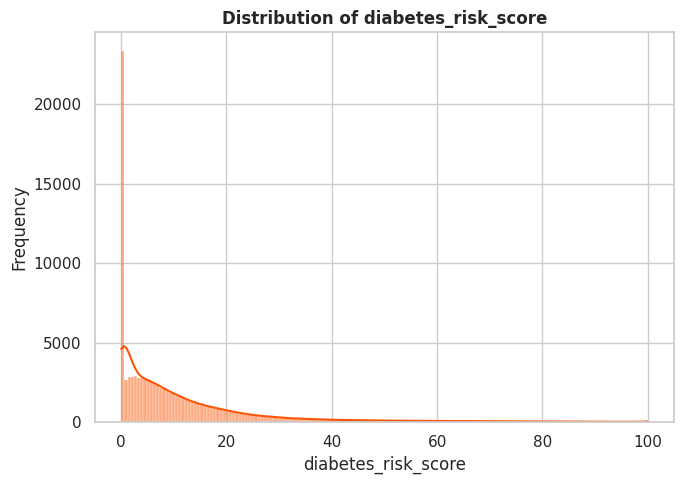

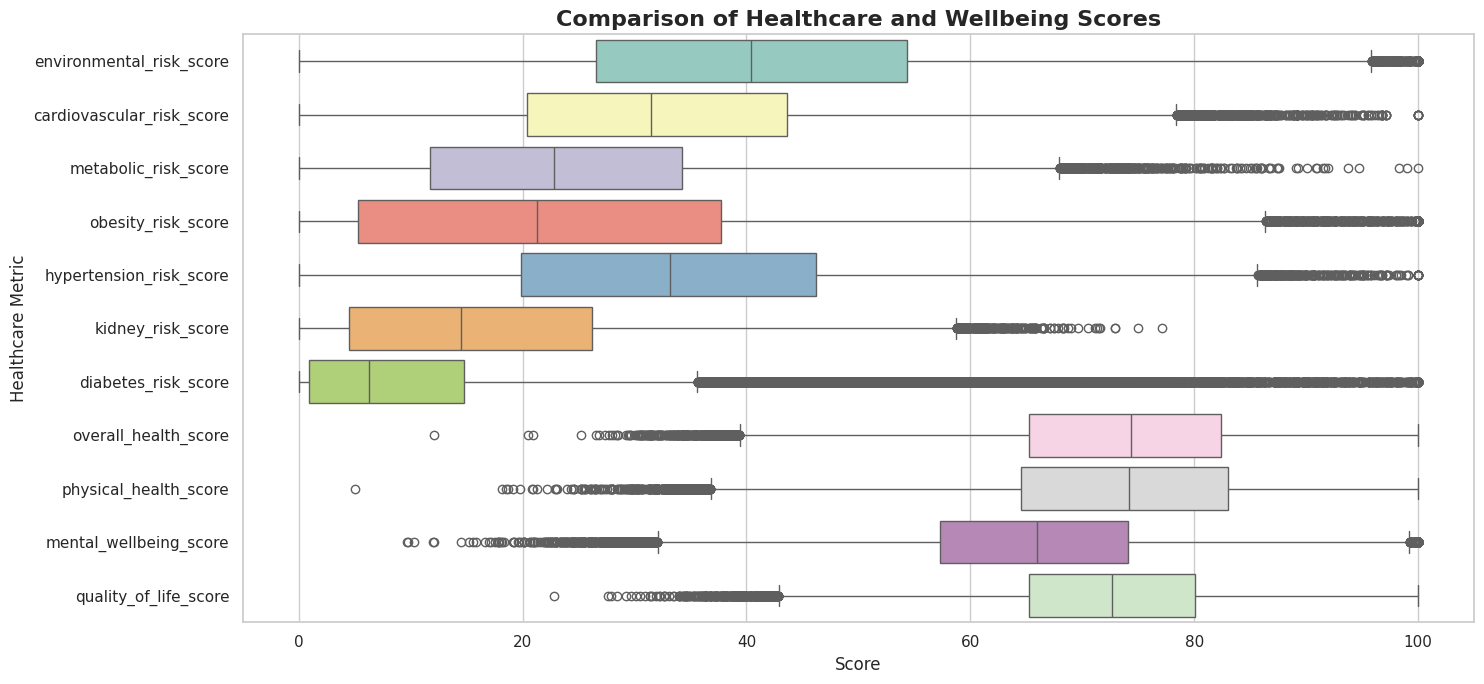

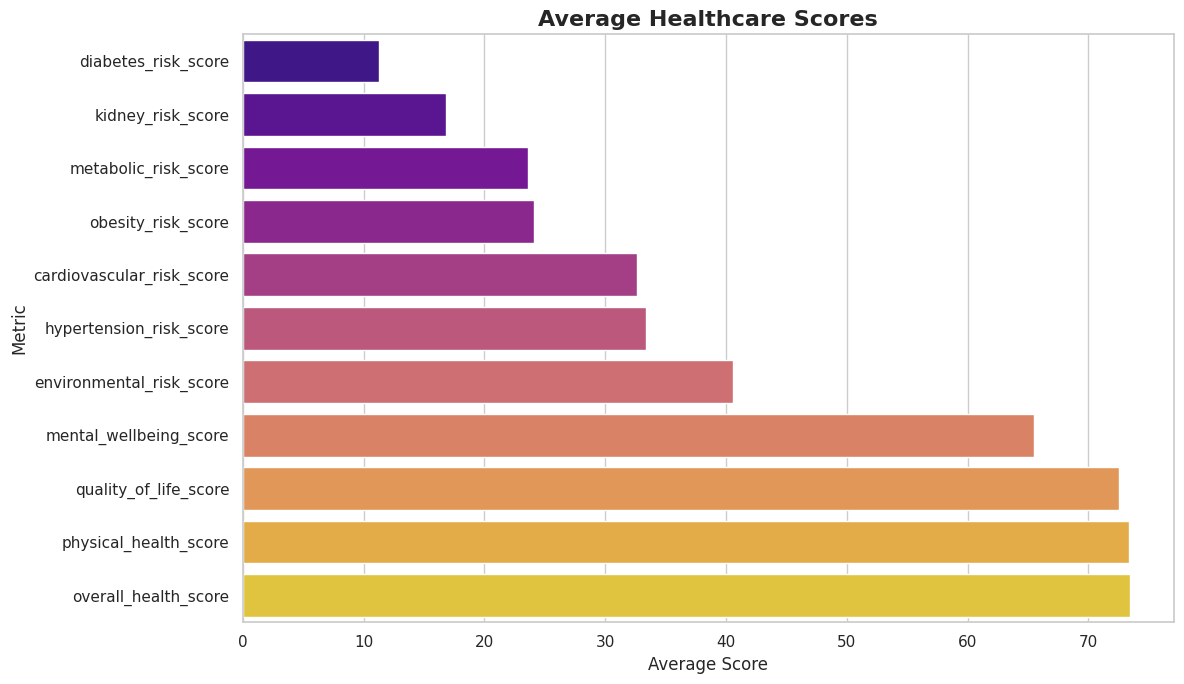

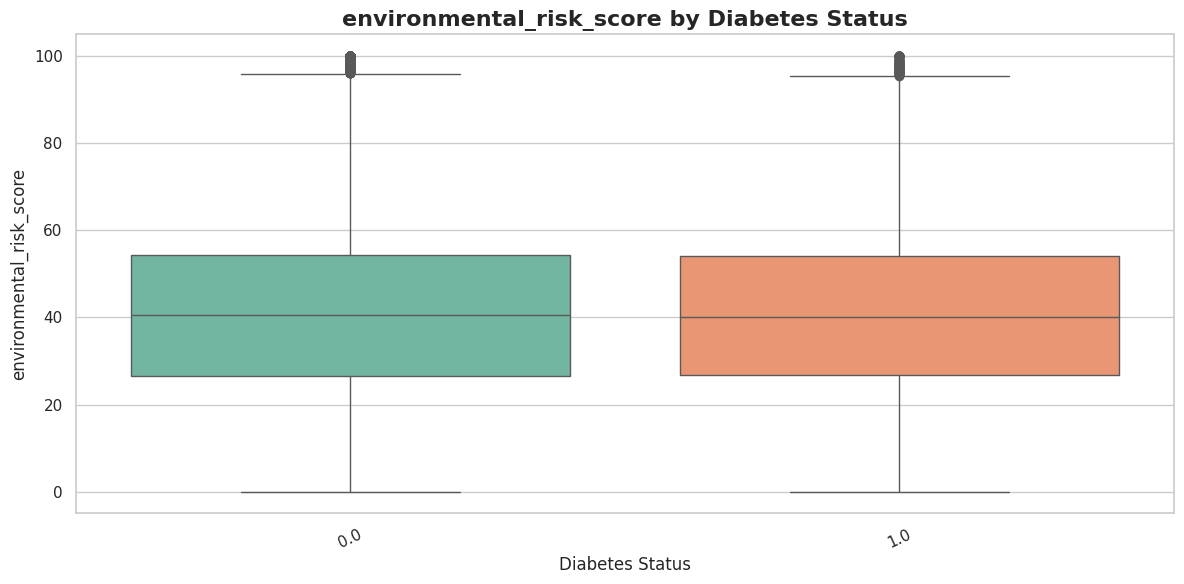

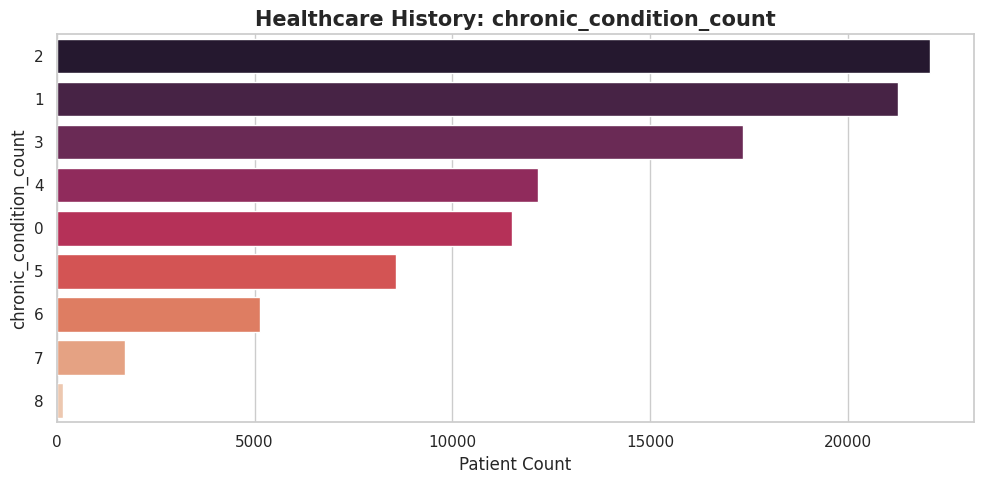

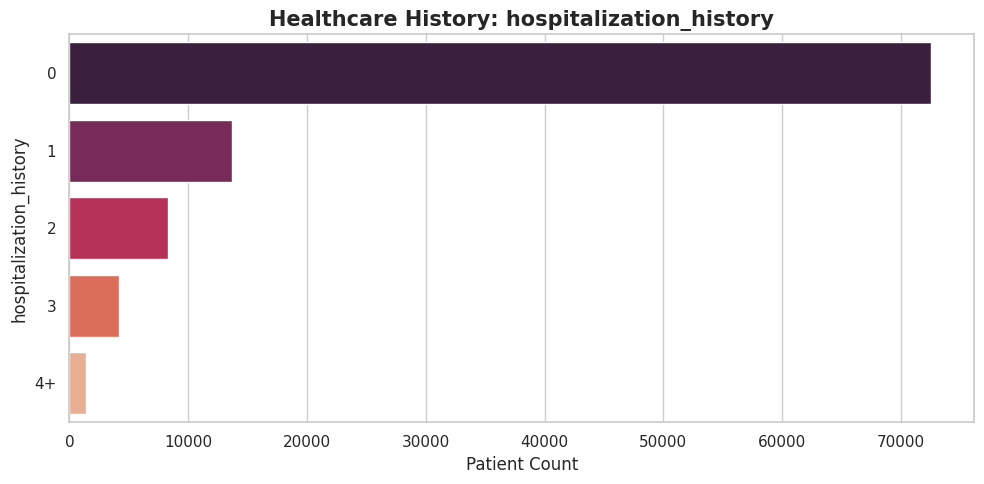

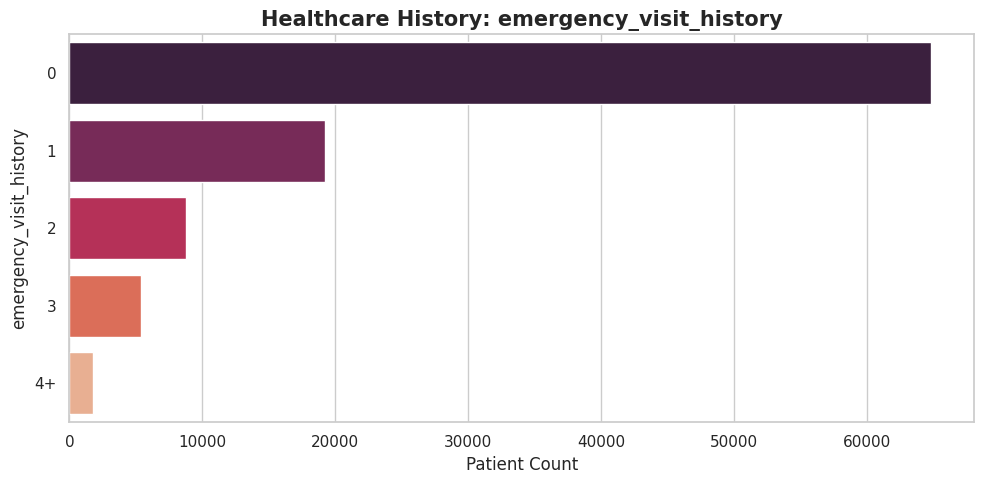

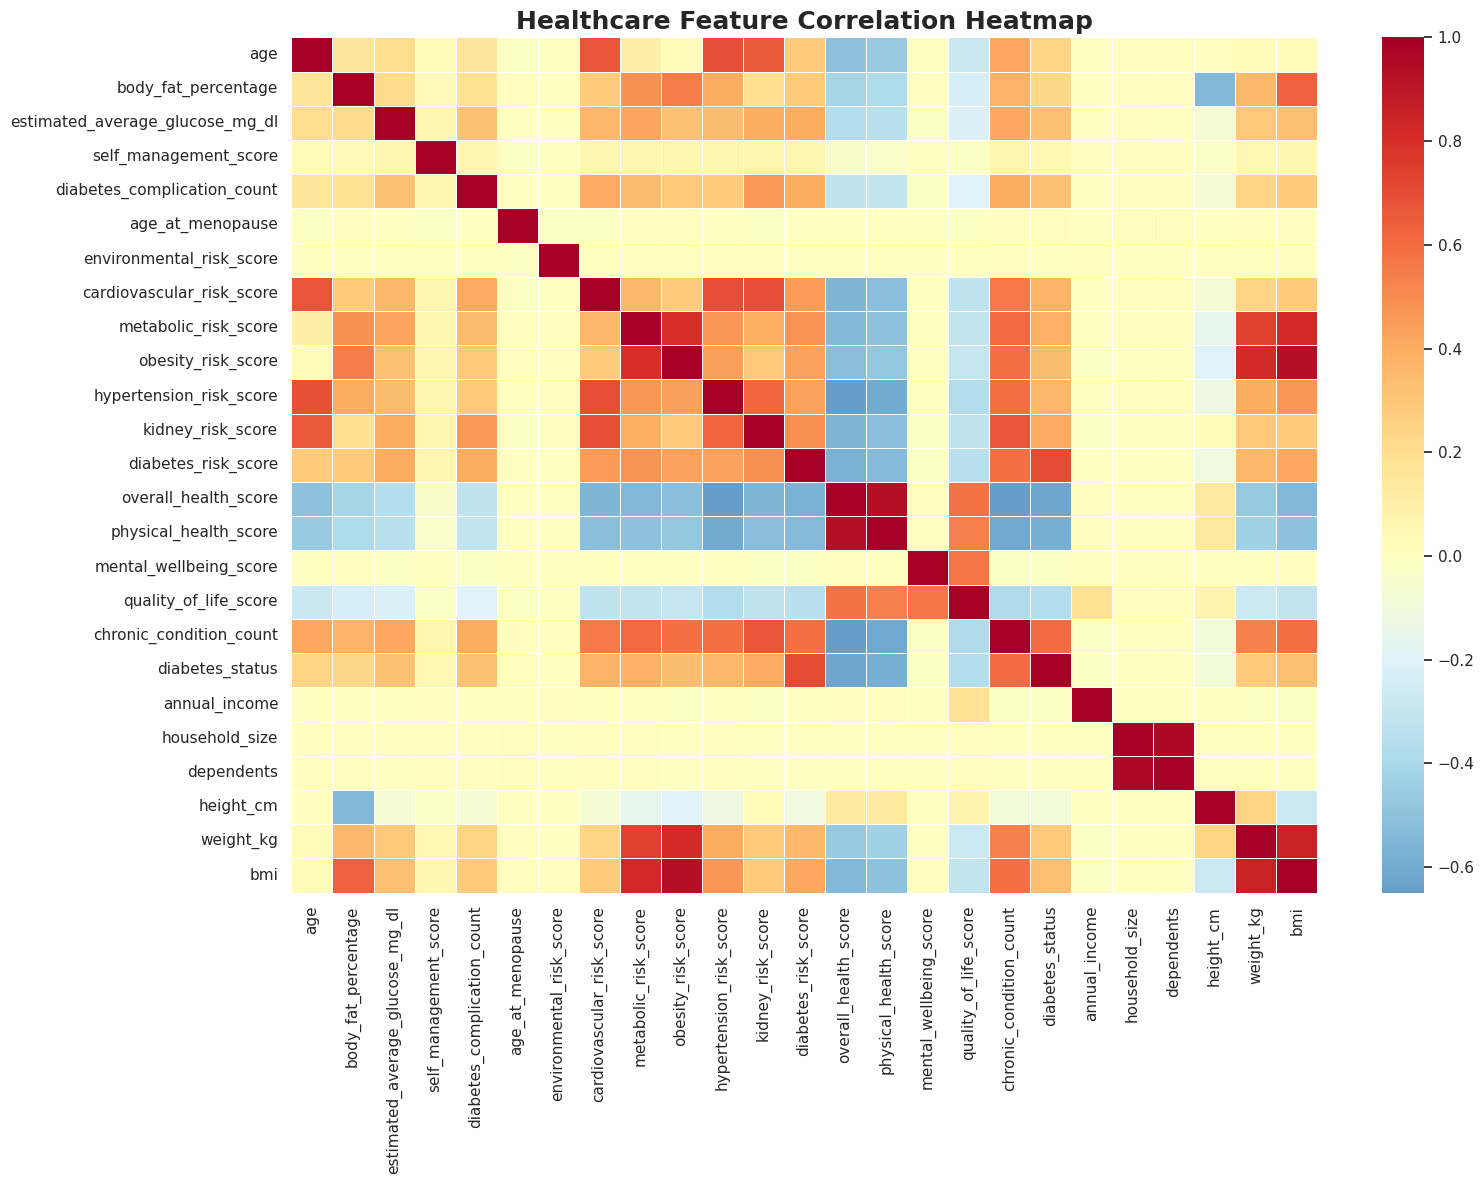

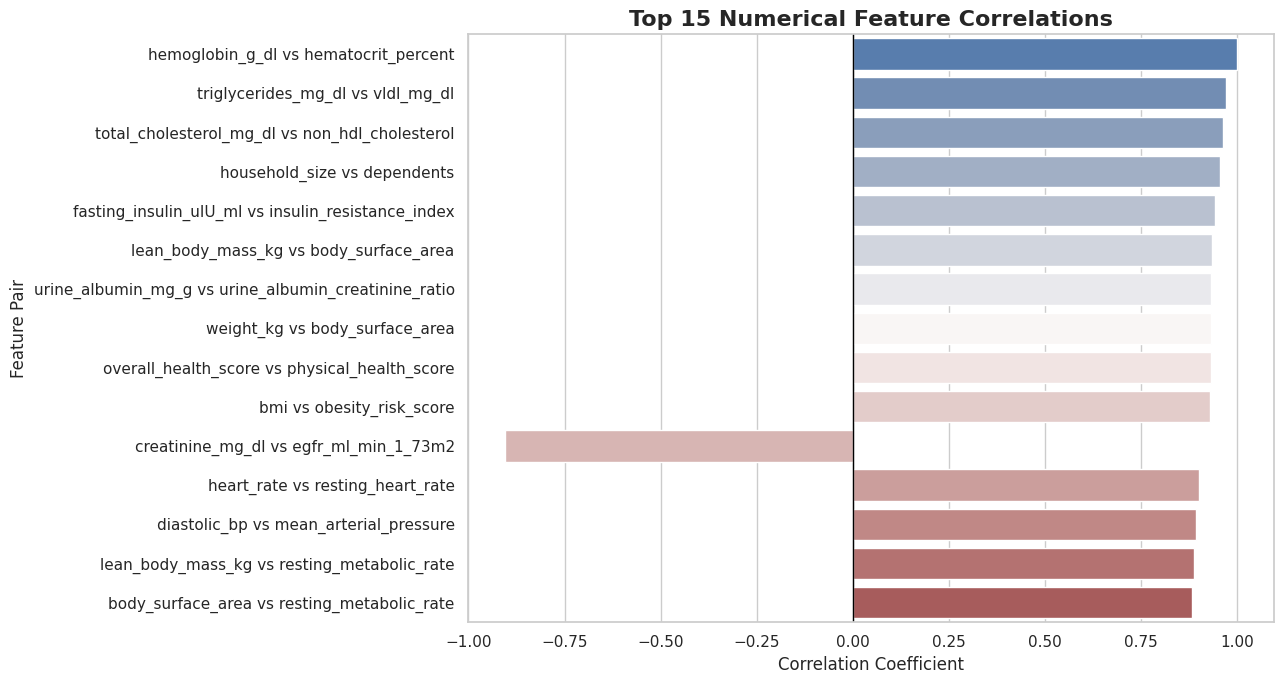

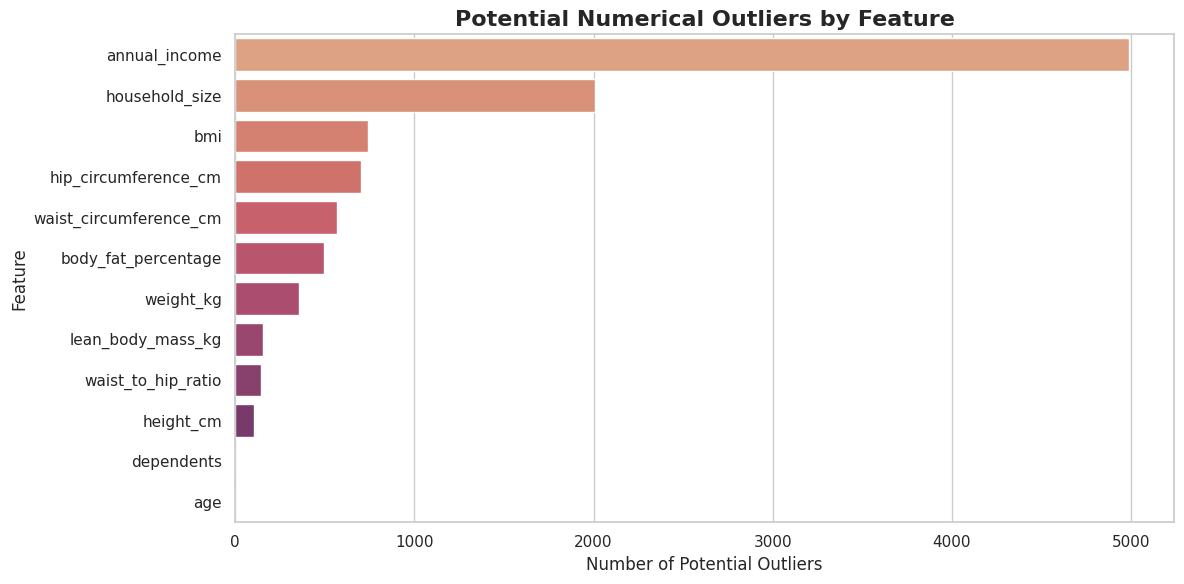

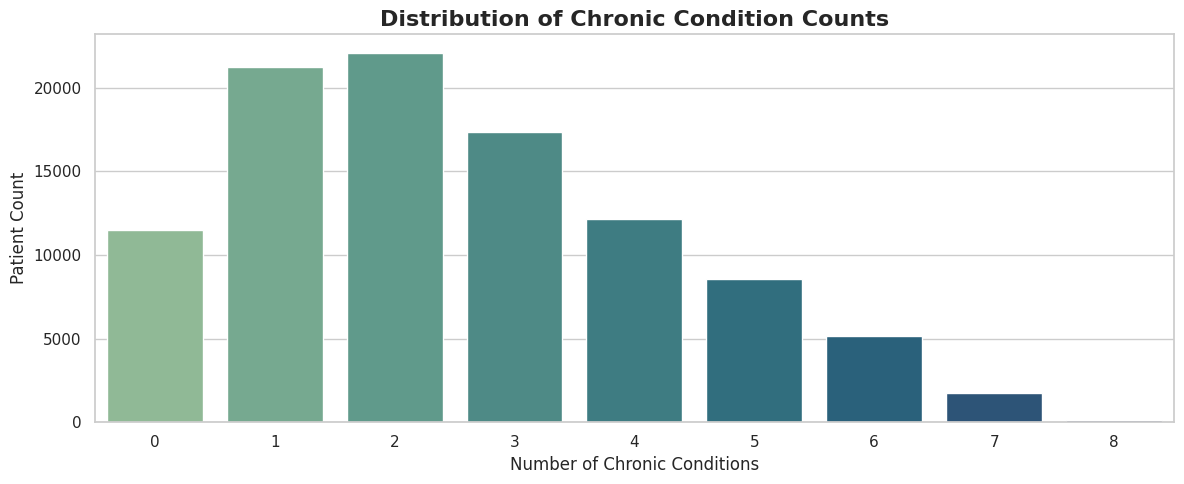

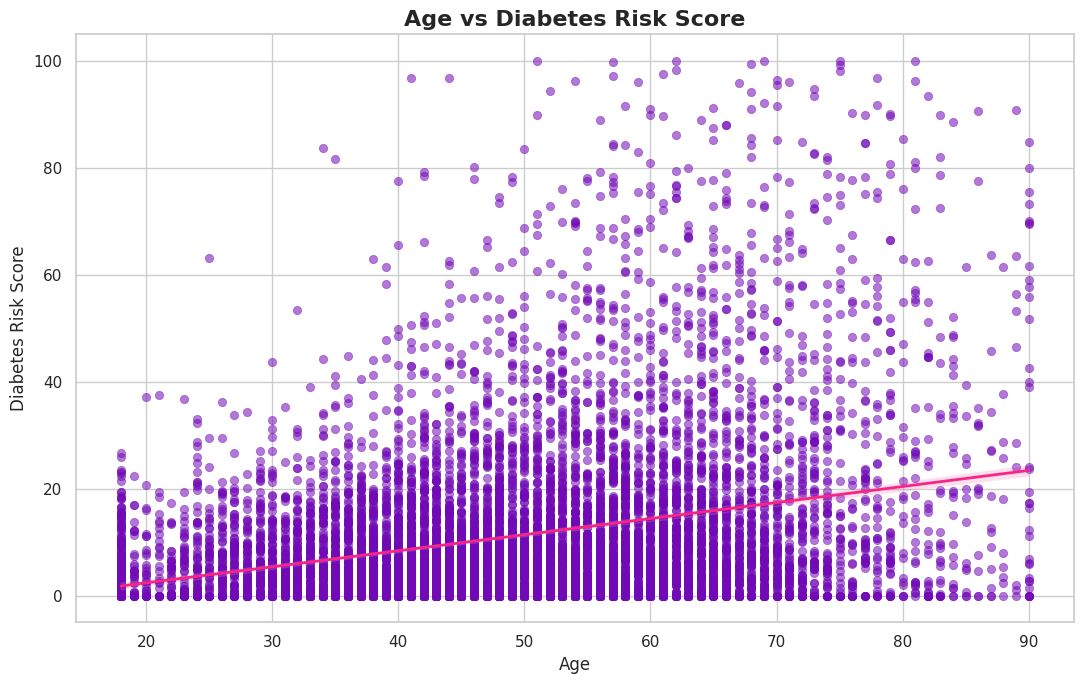


NUMERICAL STATISTICAL SUMMARY


,count,mean,std,min,25%,50%,75%,max
age,98007.0,49.599,14.734,18.0,39.000,50.000,60.00,90.00
annual_income,100000.0,61622.163,42453.523,10000.0,30194.305,51370.585,79948.43,282671.22
household_size,100000.0,3.218,1.679,1.0,2.000,3.000,4.00,8.00
dependents,100000.0,1.784,1.625,0.0,0.000,2.000,3.00,6.00
height_cm,95043.0,168.337,9.398,140.0,161.400,168.000,175.20,203.00
...,...,...,...,...,...,...,...,...
physical_health_score,100000.0,73.377,13.449,5.0,64.500,74.200,83.00,100.00
mental_wellbeing_score,100000.0,65.487,12.571,9.7,57.300,66.000,74.10,100.00
quality_of_life_score,100000.0,72.500,10.934,22.8,65.200,72.700,80.10,100.00
chronic_condition_count,100000.0,2.533,1.770,0.0,1.000,2.000,4.00,8.00



CATEGORICAL SUMMARY

age_group:


,Count
age_group,
41-50,25174
51-60,24109
31-40,17164
61-70,15191
18-30,10256
71-90,8106



sex:


...


occupation_category:


,Count
occupation_category,
Professional,17948
Service,17939
Technical,14938
Managerial,12149
Manual,11987
Retired,10015
Unemployed,8008
Student,7016



income_level:


,Count
income_level,
Middle,29835
Upper-Middle,22201
Lower-Middle,21865
Low,14963
High,11136



All applicable healthcare visualizations completed.


In [13]:

from IPython.display import display
# Use your existing DataFrame
if "df" not in globals():
    raise NameError("Please load your healthcare dataset into a DataFrame named df.")

df = df.copy()

# Remove duplicate column names for safer plotting
df = df.loc[:, ~df.columns.duplicated()].copy()

# Different colors for visualizations
sns.set_theme(style="whitegrid", context="notebook")

COLORS = [
    "#4361EE", "#F72585", "#4CC9F0", "#7209B7",
    "#F77F00", "#06D6A0", "#EF476F", "#118AB2",
    "#FFD166", "#8338EC", "#3A86FF", "#FB5607",
    "#2A9D8F", "#E76F51", "#8AC926", "#FF006E"
]

print("=" * 70)
print("HEALTHCARE DATASET OVERVIEW")
print("=" * 70)
print("Dataset shape:", df.shape)
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

print("\nFirst 5 records:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.value_counts().rename_axis("Data Type").to_frame("Count"))

print("\nMissing values:")
missing_summary = df.isnull().sum()
missing_summary = missing_summary[missing_summary > 0].sort_values(ascending=False)
display(missing_summary.head(30).to_frame("Missing Values"))

# ------------------------------------------------------------
# 2. AUTOMATICALLY IDENTIFY COLUMN TYPES
# ------------------------------------------------------------

# Exclude identifiers from statistical plots
id_cols = [
    c for c in df.columns
    if c.lower() in ["patient_id", "record_id", "id"]
    or c.lower().endswith("_id")
]

numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

numeric_analysis_cols = [
    c for c in numeric_cols
    if c not in id_cols
    and df[c].nunique(dropna=True) > 1
]

categorical_cols = df.select_dtypes(
    include=["object", "category", "bool", "string"]
).columns.tolist()

# Identify useful healthcare columns automatically
def find_cols(keywords, columns=None):
    columns = list(df.columns) if columns is None else columns
    return [
        c for c in columns
        if any(word in c.lower() for word in keywords)
    ]

age_cols = find_cols(["age"], numeric_analysis_cols)
diabetes_cols = find_cols(["diabetes"], df.columns.tolist())
health_score_cols = find_cols(
    ["health_score", "wellbeing_score", "quality_of_life",
     "risk_score", "physical_health", "mental_wellbeing"],
    numeric_analysis_cols
)
history_cols = find_cols(
    ["hospitalization", "emergency_visit", "chronic_condition"],
    df.columns.tolist()
)
demographic_cols = find_cols(
    ["sex", "gender", "ethnicity", "race_group", "marital_status",
     "education_level"],
    categorical_cols
)

print("\nNumeric columns:", len(numeric_analysis_cols))
print("Categorical columns:", len(categorical_cols))
print("Identifier columns:", id_cols)
print("Age columns:", age_cols)
print("Diabetes columns:", diabetes_cols)
print("Health score columns:", health_score_cols)

# ------------------------------------------------------------
# 3. MISSING VALUE VISUALIZATION
# ------------------------------------------------------------

plt.figure(figsize=(15, 7))

missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
missing_pct = missing_pct[missing_pct > 0].head(30)

if len(missing_pct):
    ax = sns.barplot(
        x=missing_pct.values,
        y=missing_pct.index,
        hue=missing_pct.index,
        palette="magma",
        legend=False
    )
    plt.title("Top 30 Columns by Missing Value Percentage",
              fontsize=16, fontweight="bold")
    plt.xlabel("Missing Values (%)")
    plt.ylabel("Column")
    plt.tight_layout()
    plt.show()
else:
    print("No missing values found.")

# ------------------------------------------------------------
# 4. NUMERICAL FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

# Select up to 12 numeric features for readable plots
selected_numeric = numeric_analysis_cols[:12]

if selected_numeric:
    rows = int(np.ceil(len(selected_numeric) / 3))
    fig, axes = plt.subplots(rows, 3, figsize=(18, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(selected_numeric):
        values = pd.to_numeric(df[col], errors="coerce").dropna()

        sns.histplot(
            values,
            kde=True,
            color=COLORS[i % len(COLORS)],
            ax=axes[i]
        )
        axes[i].set_title(f"Distribution of {col}", fontweight="bold")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")

    for j in range(len(selected_numeric), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle("Numerical Feature Distributions",
                 fontsize=20, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 5. CATEGORICAL FEATURE DISTRIBUTIONS
# ------------------------------------------------------------

# Avoid plotting all 200+ columns at once
selected_categorical = [
    c for c in categorical_cols
    if 1 < df[c].nunique(dropna=True) <= 20
][:12]

if selected_categorical:
    rows = int(np.ceil(len(selected_categorical) / 3))
    fig, axes = plt.subplots(rows, 3, figsize=(19, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(selected_categorical):
        counts = df[col].fillna("Missing").astype(str).value_counts().head(12)

        sns.barplot(
            x=counts.values,
            y=counts.index,
            hue=counts.index,
            palette="Spectral",
            legend=False,
            ax=axes[i]
        )

        axes[i].set_title(f"Category Counts: {col}", fontweight="bold")
        axes[i].set_xlabel("Number of Records")
        axes[i].set_ylabel(col)

    for j in range(len(selected_categorical), len(axes)):
        axes[j].set_visible(False)

    plt.suptitle("Categorical Feature Analysis",
                 fontsize=20, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 6. AGE DISTRIBUTION
# ------------------------------------------------------------

age_col = next(
    (c for c in age_cols if c.lower() == "age"),
    age_cols[0] if age_cols else None
)

if age_col:
    age_values = pd.to_numeric(df[age_col], errors="coerce").dropna()

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    sns.histplot(
        age_values,
        bins=25,
        kde=True,
        color="#4361EE",
        ax=axes[0]
    )
    axes[0].set_title("Patient Age Distribution", fontweight="bold")
    axes[0].set_xlabel("Age")
    axes[0].set_ylabel("Patient Count")

    sns.boxplot(
        x=age_values,
        color="#F72585",
        ax=axes[1]
    )
    axes[1].set_title("Patient Age Boxplot", fontweight="bold")
    axes[1].set_xlabel("Age")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 7. AGE GROUP ANALYSIS
# ------------------------------------------------------------

age_group_col = next(
    (c for c in df.columns if c.lower() == "age_group"),
    None
)

if age_group_col:
    age_counts = df[age_group_col].fillna("Missing").astype(str).value_counts()

    plt.figure(figsize=(12, 6))
    plt.pie(
        age_counts.values,
        labels=age_counts.index,
        autopct="%1.1f%%",
        startangle=140,
        colors=COLORS[:len(age_counts)],
        wedgeprops={"edgecolor": "white", "linewidth": 1.5}
    )
    plt.title("Patient Distribution by Age Group",
              fontsize=16, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 8. SEX AND GENDER DISTRIBUTION
# ------------------------------------------------------------

sex_gender_cols = [
    c for c in df.columns
    if c.lower() in ["sex", "gender"]
]

if sex_gender_cols:
    fig, axes = plt.subplots(
        1, len(sex_gender_cols),
        figsize=(7 * len(sex_gender_cols), 5)
    )
    axes = np.atleast_1d(axes)

    for i, col in enumerate(sex_gender_cols):
        counts = df[col].fillna("Missing").astype(str).value_counts()

        sns.barplot(
            x=counts.index,
            y=counts.values,
            hue=counts.index,
            palette="Set2",
            legend=False,
            ax=axes[i]
        )
        axes[i].set_title(f"Distribution by {col}", fontweight="bold")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Patient Count")
        axes[i].tick_params(axis="x", rotation=30)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 9. DEMOGRAPHIC ANALYSIS
# ------------------------------------------------------------

selected_demo = [
    c for c in demographic_cols
    if df[c].nunique(dropna=True) > 1
][:8]

if selected_demo:
    rows = int(np.ceil(len(selected_demo) / 2))
    fig, axes = plt.subplots(rows, 2, figsize=(16, 5 * rows))
    axes = np.array(axes).reshape(-1)

    for i, col in enumerate(selected_demo):
        counts = df[col].fillna("Missing").astype(str).value_counts().head(10)

        sns.barplot(
            x=counts.values,
            y=counts.index,
            hue=counts.index,
            palette="viridis",
            legend=False,
            ax=axes[i]
        )
        axes[i].set_title(f"Demographic Analysis: {col}", fontweight="bold")
        axes[i].set_xlabel("Patient Count")
        axes[i].set_ylabel(col)

    for j in range(len(selected_demo), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 10. DIABETES STATUS ANALYSIS
# ------------------------------------------------------------

diabetes_status_col = next(
    (c for c in df.columns if c.lower() == "diabetes_status"),
    None
)

if diabetes_status_col:
    counts = df[diabetes_status_col].fillna("Missing").astype(str).value_counts()

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    sns.barplot(
        x=counts.index,
        y=counts.values,
        hue=counts.index,
        palette="Set1",
        legend=False,
        ax=axes[0]
    )
    axes[0].set_title("Diabetes Status Counts", fontweight="bold")
    axes[0].set_xlabel("Diabetes Status")
    axes[0].set_ylabel("Patient Count")
    axes[0].tick_params(axis="x", rotation=25)

    axes[1].pie(
        counts.values,
        labels=counts.index,
        autopct="%1.1f%%",
        colors=COLORS[:len(counts)],
        startangle=90
    )
    axes[1].set_title("Diabetes Status Percentage", fontweight="bold")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 11. DIABETES TYPE ANALYSIS
# ------------------------------------------------------------

diabetes_type_col = next(
    (c for c in df.columns if c.lower() == "diabetes_type"),
    None
)

if diabetes_type_col:
    counts = df[diabetes_type_col].fillna("Missing").astype(str).value_counts()

    plt.figure(figsize=(12, 6))
    sns.barplot(
        x=counts.values,
        y=counts.index,
        hue=counts.index,
        palette="coolwarm",
        legend=False
    )
    plt.title("Distribution of Diabetes Types",
              fontsize=16, fontweight="bold")
    plt.xlabel("Patient Count")
    plt.ylabel("Diabetes Type")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 12. DIABETES RISK SCORE ANALYSIS
# ------------------------------------------------------------

risk_cols = [
    c for c in numeric_analysis_cols
    if "diabetes_risk_score" in c.lower()
]

if risk_cols:
    fig, axes = plt.subplots(1, len(risk_cols), figsize=(7 * len(risk_cols), 5))
    axes = np.atleast_1d(axes)

    for i, col in enumerate(risk_cols):
        sns.histplot(
            pd.to_numeric(df[col], errors="coerce").dropna(),
            kde=True,
            color="#FB5607",
            ax=axes[i]
        )
        axes[i].set_title(f"Distribution of {col}", fontweight="bold")
        axes[i].set_xlabel(col)
        axes[i].set_ylabel("Frequency")

    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 13. HEALTH SCORE COMPARISON
# ------------------------------------------------------------

if health_score_cols:
    score_data = df[health_score_cols].apply(pd.to_numeric, errors="coerce")

    # Limit extreme number of score columns for readability
    score_data = score_data.iloc[:, :12]

    plt.figure(figsize=(15, 7))
    sns.boxplot(
        data=score_data,
        palette="Set3",
        orient="h"
    )
    plt.title("Comparison of Healthcare and Wellbeing Scores",
              fontsize=16, fontweight="bold")
    plt.xlabel("Score")
    plt.ylabel("Healthcare Metric")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

    # Compare average scores
    mean_scores = score_data.mean().sort_values()

    plt.figure(figsize=(12, 7))
    sns.barplot(
        x=mean_scores.values,
        y=mean_scores.index,
        hue=mean_scores.index,
        palette="plasma",
        legend=False
    )
    plt.title("Average Healthcare Scores",
              fontsize=16, fontweight="bold")
    plt.xlabel("Average Score")
    plt.ylabel("Metric")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 14. HEALTH SCORES BY DIABETES STATUS
# ------------------------------------------------------------

if diabetes_status_col and health_score_cols:
    score_col = health_score_cols[0]

    plot_data = df[[diabetes_status_col, score_col]].copy()
    plot_data[score_col] = pd.to_numeric(
        plot_data[score_col], errors="coerce"
    )
    plot_data = plot_data.dropna()

    if not plot_data.empty:
        plt.figure(figsize=(12, 6))
        sns.boxplot(
            data=plot_data,
            x=diabetes_status_col,
            y=score_col,
            hue=diabetes_status_col,
            palette="Set2",
            legend=False
        )
        plt.title(
            f"{score_col} by Diabetes Status",
            fontsize=16,
            fontweight="bold"
        )
        plt.xlabel("Diabetes Status")
        plt.ylabel(score_col)
        plt.xticks(rotation=25)
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 15. HOSPITALIZATION AND EMERGENCY VISIT HISTORY
# ------------------------------------------------------------

for col in history_cols[:6]:
    counts = df[col].fillna("Missing").astype(str).value_counts().head(12)

    plt.figure(figsize=(10, 5))
    sns.barplot(
        x=counts.values,
        y=counts.index,
        hue=counts.index,
        palette="rocket",
        legend=False
    )
    plt.title(f"Healthcare History: {col}", fontsize=15, fontweight="bold")
    plt.xlabel("Patient Count")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 16. CORRELATION HEATMAP
# ------------------------------------------------------------

if len(numeric_analysis_cols) >= 2:
    # Prioritize clinically meaningful columns where available
    priority_cols = [
        c for c in numeric_analysis_cols
        if any(k in c.lower() for k in [
            "age", "diabetes", "risk_score", "health_score",
            "physical_health", "mental_wellbeing",
            "quality_of_life", "chronic_condition",
            "hospitalization", "emergency_visit"
        ])
    ]

    corr_cols = list(dict.fromkeys(priority_cols + numeric_analysis_cols))[:25]
    corr_matrix = df[corr_cols].corr(numeric_only=True)

    plt.figure(figsize=(16, 12))
    sns.heatmap(
        corr_matrix,
        cmap="RdYlBu_r",
        center=0,
        annot=len(corr_cols) <= 12,
        fmt=".2f",
        linewidths=0.4,
        square=False
    )
    plt.title("Healthcare Feature Correlation Heatmap",
              fontsize=18, fontweight="bold")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 17. TOP CORRELATED NUMERICAL FEATURES
# ------------------------------------------------------------

if len(numeric_analysis_cols) >= 2:
    corr_matrix = df[numeric_analysis_cols].corr(numeric_only=True)
    upper = corr_matrix.where(
        np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
    )

    top_corr = upper.stack().rename("Correlation").to_frame()
    top_corr["Absolute Correlation"] = top_corr["Correlation"].abs()
    top_corr = top_corr.sort_values(
        "Absolute Correlation", ascending=False
    ).head(15)

    if not top_corr.empty:
        labels = [f"{a} vs {b}" for a, b in top_corr.index]

        plt.figure(figsize=(13, 7))
        sns.barplot(
            x=top_corr["Correlation"].values,
            y=labels,
            hue=labels,
            palette="vlag",
            legend=False
        )
        plt.axvline(0, color="black", linewidth=1)
        plt.title("Top 15 Numerical Feature Correlations",
                  fontsize=16, fontweight="bold")
        plt.xlabel("Correlation Coefficient")
        plt.ylabel("Feature Pair")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 18. OUTLIER ANALYSIS
# ------------------------------------------------------------

outlier_cols = numeric_analysis_cols[:12]

if outlier_cols:
    outlier_counts = {}

    for col in outlier_cols:
        values = pd.to_numeric(df[col], errors="coerce").dropna()

        if len(values) < 4:
            continue

        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        if iqr == 0:
            outlier_counts[col] = 0
        else:
            lower = q1 - 1.5 * iqr
            upper_bound = q3 + 1.5 * iqr
            outlier_counts[col] = int(
                ((values < lower) | (values > upper_bound)).sum()
            )

    if outlier_counts:
        outlier_series = pd.Series(outlier_counts).sort_values(ascending=False)

        plt.figure(figsize=(12, 6))
        sns.barplot(
            x=outlier_series.values,
            y=outlier_series.index,
            hue=outlier_series.index,
            palette="flare",
            legend=False
        )
        plt.title("Potential Numerical Outliers by Feature",
                  fontsize=16, fontweight="bold")
        plt.xlabel("Number of Potential Outliers")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 19. CHRONIC CONDITION COUNT ANALYSIS
# ------------------------------------------------------------

chronic_col = next(
    (c for c in df.columns if c.lower() == "chronic_condition_count"),
    None
)

if chronic_col:
    chronic_values = pd.to_numeric(
        df[chronic_col], errors="coerce"
    ).dropna()

    counts = chronic_values.value_counts().sort_index()

    plt.figure(figsize=(12, 5))
    sns.barplot(
        x=counts.index.astype(str),
        y=counts.values,
        hue=counts.index.astype(str),
        palette="crest",
        legend=False
    )
    plt.title("Distribution of Chronic Condition Counts",
              fontsize=16, fontweight="bold")
    plt.xlabel("Number of Chronic Conditions")
    plt.ylabel("Patient Count")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 20. AGE VS DIABETES RISK SCATTER PLOT
# ------------------------------------------------------------

risk_col = next(
    (c for c in numeric_analysis_cols
     if "diabetes_risk_score" in c.lower()),
    None
)

if age_col and risk_col:
    scatter_data = df[[age_col, risk_col]].apply(
        pd.to_numeric, errors="coerce"
    ).dropna()

    if not scatter_data.empty:
        # Sample only for plotting if the dataset is very large
        if len(scatter_data) > 10000:
            scatter_data = scatter_data.sample(
                10000, random_state=42
            )

        plt.figure(figsize=(11, 7))
        sns.scatterplot(
            data=scatter_data,
            x=age_col,
            y=risk_col,
            alpha=0.55,
            color="#7209B7",
            edgecolor=None
        )
        sns.regplot(
            data=scatter_data,
            x=age_col,
            y=risk_col,
            scatter=False,
            color="#F72585",
            line_kws={"linewidth": 2}
        )
        plt.title("Age vs Diabetes Risk Score",
                  fontsize=16, fontweight="bold")
        plt.xlabel("Age")
        plt.ylabel("Diabetes Risk Score")
        plt.tight_layout()
        plt.show()

# ------------------------------------------------------------
# 21. AUTOMATIC NUMERIC SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("NUMERICAL STATISTICAL SUMMARY")
print("=" * 70)

if numeric_analysis_cols:
    display(df[numeric_analysis_cols].describe().T.round(3))

print("\n" + "=" * 70)
print("CATEGORICAL SUMMARY")
print("=" * 70)

for col in selected_categorical[:10]:
    print(f"\n{col}:")
    display(
        df[col].value_counts(dropna=False).head(10).to_frame("Count")
    )

print("\nAll applicable healthcare visualizations completed.")


## Feature engineering

HEALTHCARE MACHINE LEARNING
Dataset shape: (100000, 209)
Prediction target: diabetes_status
Test size: 0.2

Target distribution:
diabetes_status
0.0    70573
1.0    27407
Name: count, dtype: int64

Removed identifier columns: ['patient_id', 'record_id']
Removed datetime columns: []
Removed high-cardinality columns: ['patient_id', 'record_id']
Removed target leakage candidates: ['diabetes_risk_score', 'diabetes_type']
Removed empty/constant columns: 0
Predictor count: 204

Target label mapping:
0.0 -> 0
1.0 -> 1

Numerical features: 115
Categorical features: 89

Training feature shape: (78384, 204)
Testing feature shape: (19596, 204)
Training samples: 78384
Testing samples: 19596

TRAINING: Logistic Regression
Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1 Score:  1.0000
ROC AUC:   1.0000

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     14115
         1.0       1.00      1.00      1.00      5481

   

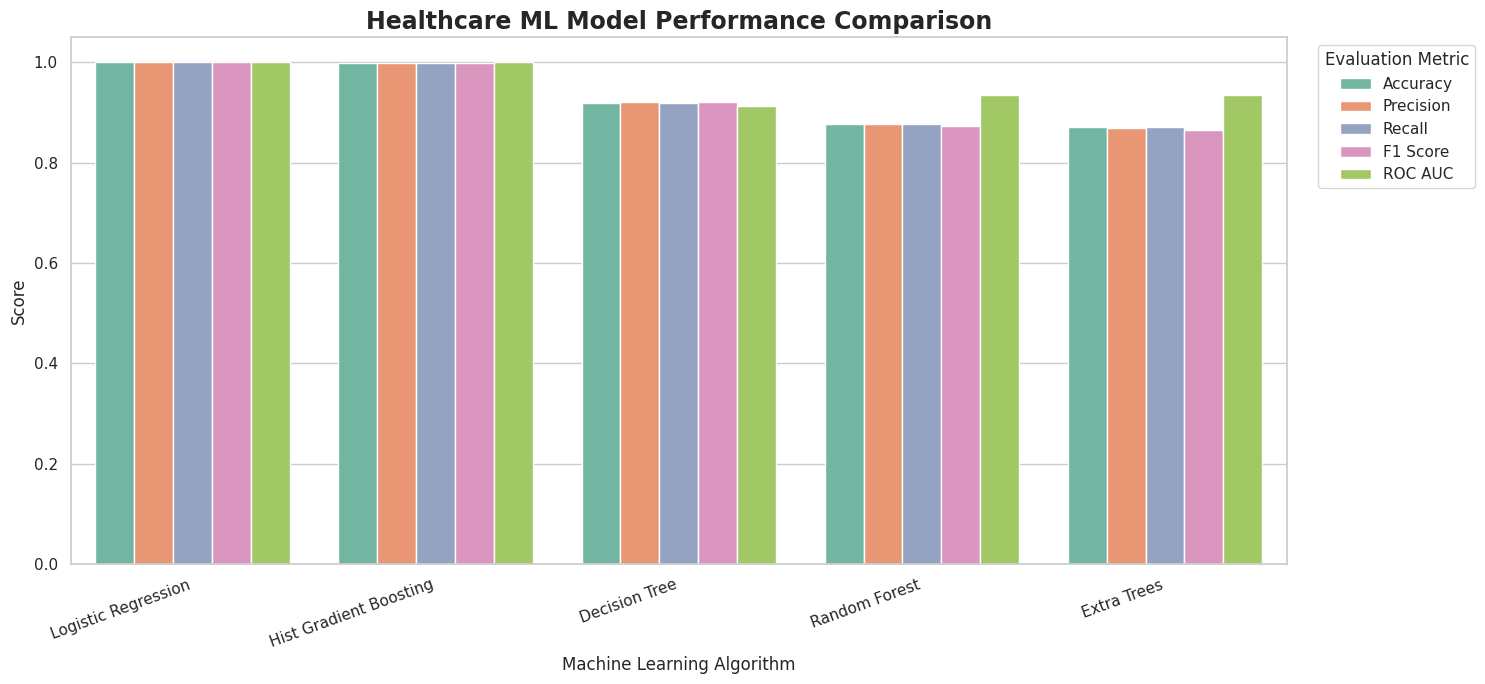

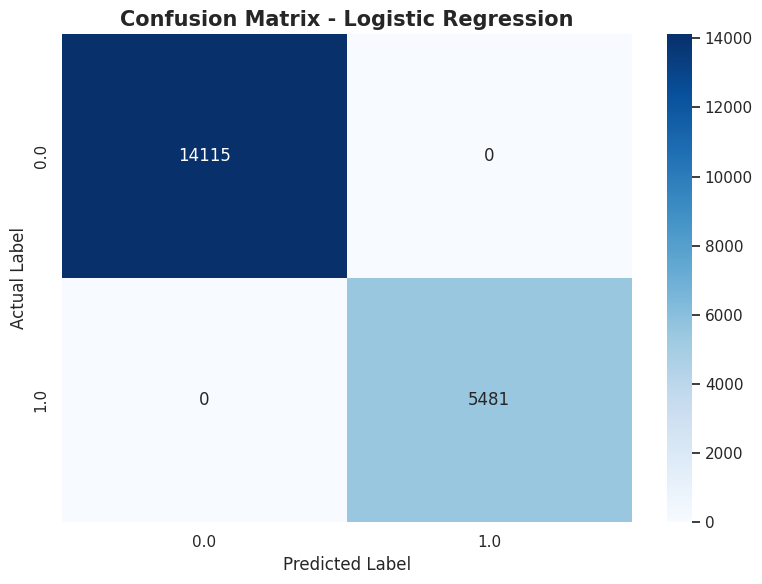

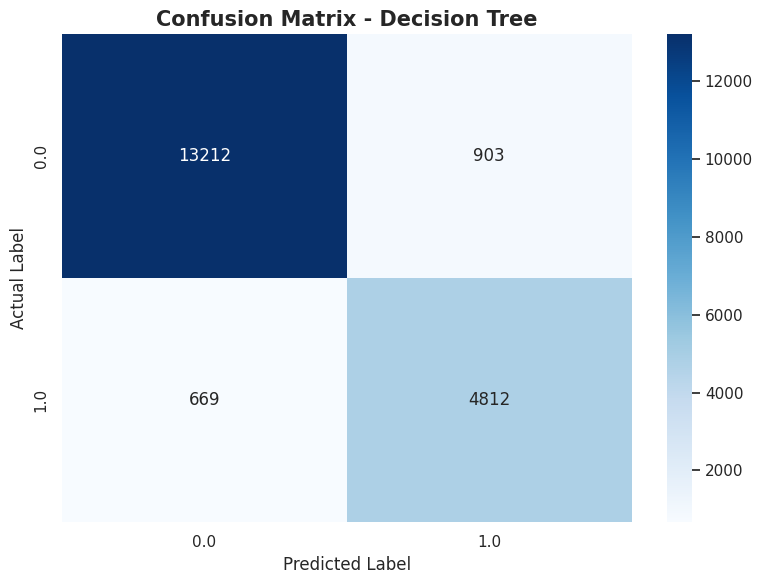

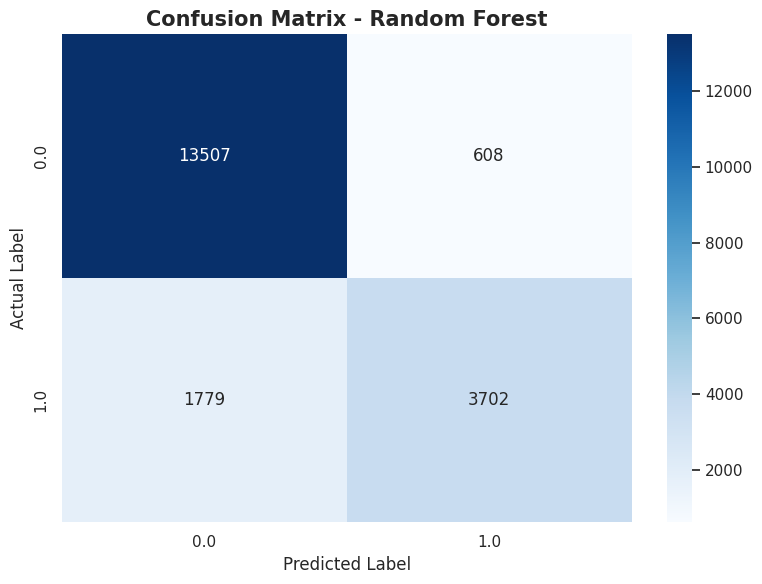

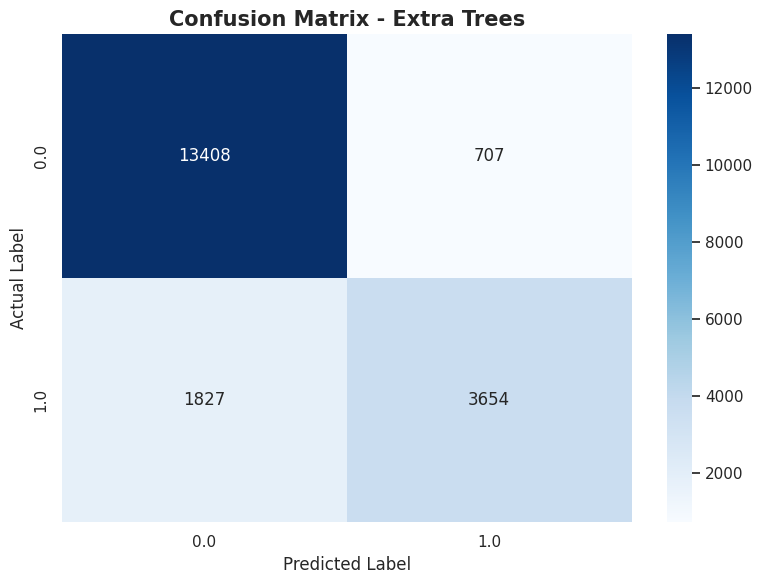

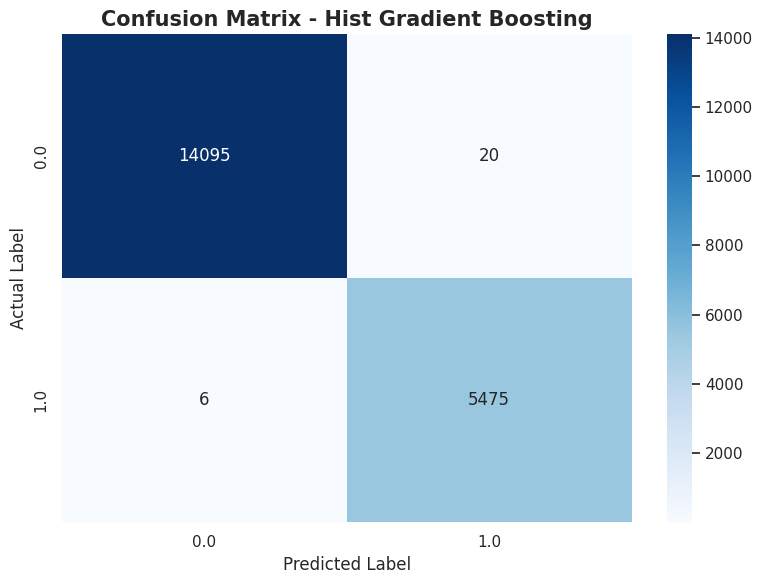

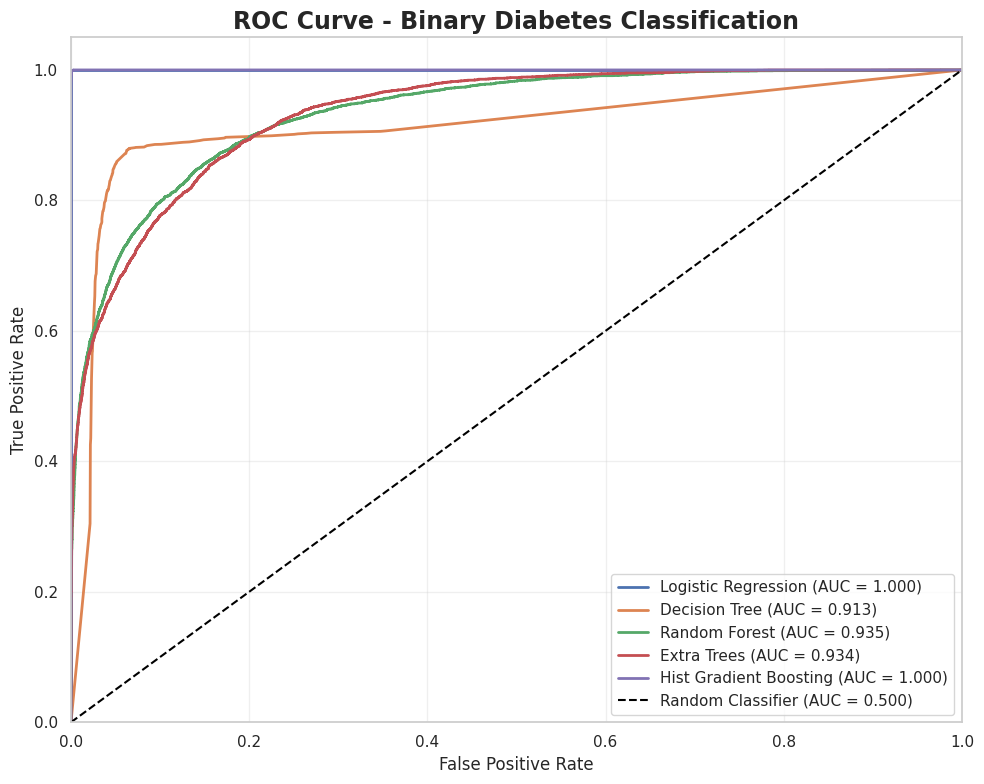

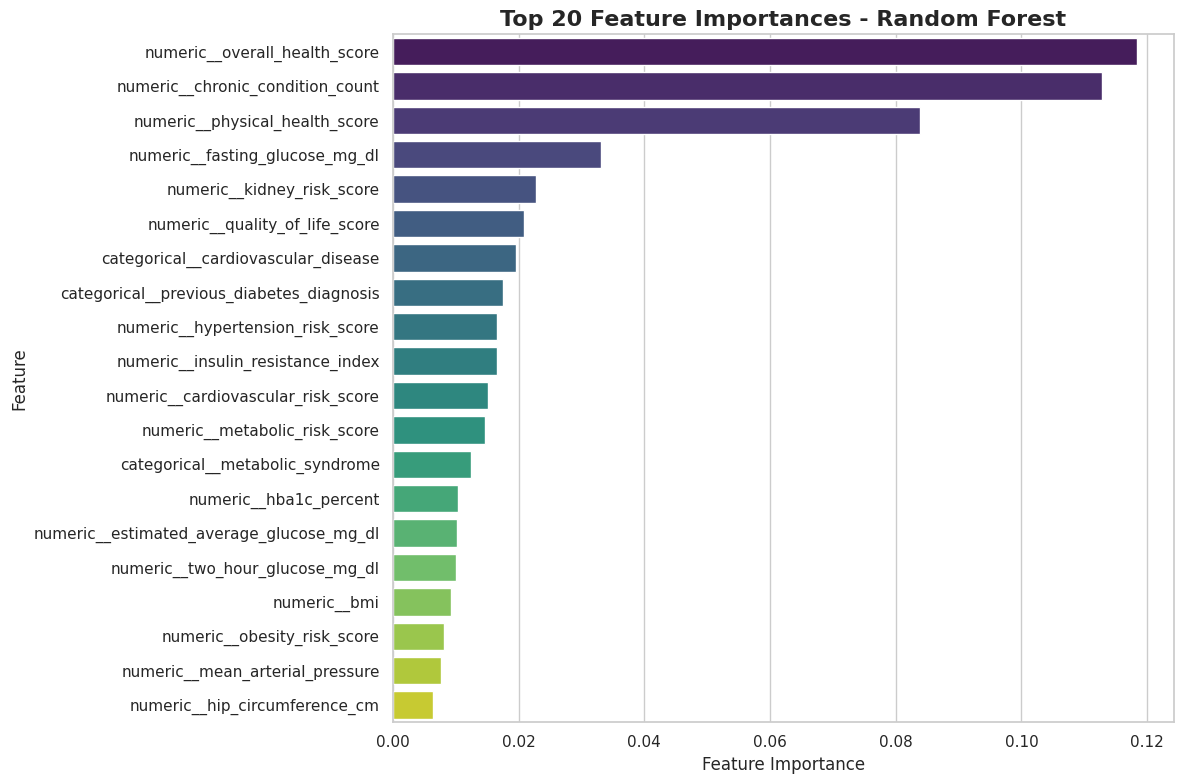


Top 20 features - Random Forest
                                 Feature  Importance
           numeric__overall_health_score    0.118367
        numeric__chronic_condition_count    0.112793
          numeric__physical_health_score    0.083830
          numeric__fasting_glucose_mg_dl    0.033083
              numeric__kidney_risk_score    0.022701
          numeric__quality_of_life_score    0.020814
     categorical__cardiovascular_disease    0.019648
categorical__previous_diabetes_diagnosis    0.017556
        numeric__hypertension_risk_score    0.016489
       numeric__insulin_resistance_index    0.016474
      numeric__cardiovascular_risk_score    0.015104
           numeric__metabolic_risk_score    0.014672
         categorical__metabolic_syndrome    0.012474
                  numeric__hba1c_percent    0.010308
numeric__estimated_average_glucose_mg_dl    0.010221
         numeric__two_hour_glucose_mg_dl    0.010051
                            numeric__bmi    0.009291
             

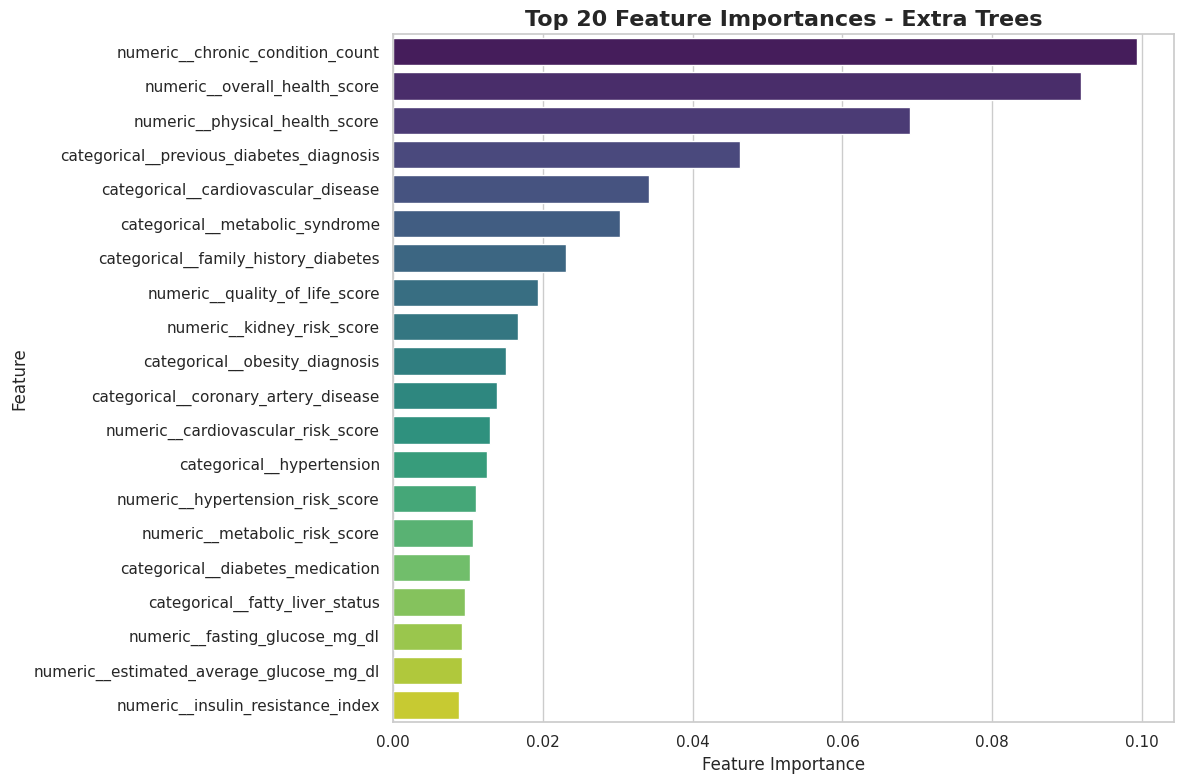


Top 20 features - Extra Trees
                                 Feature  Importance
        numeric__chronic_condition_count    0.099295
           numeric__overall_health_score    0.091793
          numeric__physical_health_score    0.069022
categorical__previous_diabetes_diagnosis    0.046289
     categorical__cardiovascular_disease    0.034116
         categorical__metabolic_syndrome    0.030311
    categorical__family_history_diabetes    0.023093
          numeric__quality_of_life_score    0.019294
              numeric__kidney_risk_score    0.016638
          categorical__obesity_diagnosis    0.015110
    categorical__coronary_artery_disease    0.013831
      numeric__cardiovascular_risk_score    0.012893
               categorical__hypertension    0.012605
        numeric__hypertension_risk_score    0.011136
           numeric__metabolic_risk_score    0.010678
        categorical__diabetes_medication    0.010259
         categorical__fatty_liver_status    0.009626
          numer

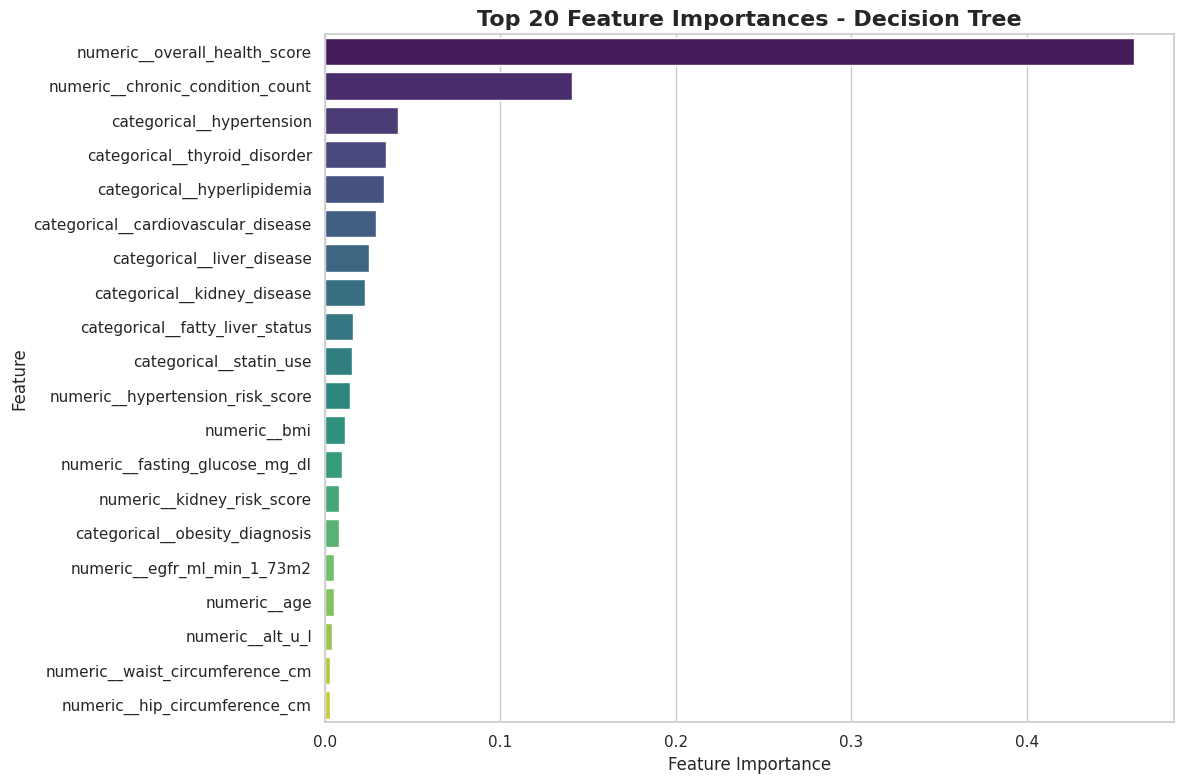


Top 20 features - Decision Tree
                            Feature  Importance
      numeric__overall_health_score    0.461012
   numeric__chronic_condition_count    0.140818
          categorical__hypertension    0.041512
      categorical__thyroid_disorder    0.034954
        categorical__hyperlipidemia    0.033803
categorical__cardiovascular_disease    0.029212
         categorical__liver_disease    0.024917
        categorical__kidney_disease    0.022591
    categorical__fatty_liver_status    0.015830
            categorical__statin_use    0.015353
   numeric__hypertension_risk_score    0.014046
                       numeric__bmi    0.011160
     numeric__fasting_glucose_mg_dl    0.009499
         numeric__kidney_risk_score    0.008002
     categorical__obesity_diagnosis    0.007799
        numeric__egfr_ml_min_1_73m2    0.005158
                       numeric__age    0.005137
                   numeric__alt_u_l    0.003743
    numeric__waist_circumference_cm    0.002968
      n

In [14]:

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    roc_auc_score
)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

# ================================================================
# 1. CONFIGURATION
# ================================================================

if "df" not in globals():
    raise NameError("Load your dataset into a DataFrame named df first.")

df = df.copy()
df = df.loc[:, ~df.columns.duplicated()].copy()

# Automatically use diabetes_status when available.
# Change to "diabetes_type" if that is the prediction target.
TARGET = (
    "diabetes_status"
    if "diabetes_status" in df.columns
    else "diabetes_type"
    if "diabetes_type" in df.columns
    else None
)

# If neither target exists, specify the correct target manually.
if TARGET is None:
    raise ValueError(
        "Target column not found. Set TARGET to the exact name "
        "of the column you want to predict."
    )

# Adjust according to your dataset and available RAM.
TEST_SIZE = 0.20
RANDOM_STATE = 42

print("=" * 70)
print("HEALTHCARE MACHINE LEARNING")
print("=" * 70)
print("Dataset shape:", df.shape)
print("Prediction target:", TARGET)
print("Test size:", TEST_SIZE)

# ================================================================
# 2. DATA CLEANING
# ================================================================

# Convert infinite numeric values to missing values
df.replace([np.inf, -np.inf], np.nan, inplace=True)

# Remove records without a target
df = df.dropna(subset=[TARGET]).copy()

# Remove target classes with fewer than 2 samples because
# stratified train-test splitting requires adequate class counts.
class_counts = df[TARGET].value_counts()
valid_classes = class_counts[class_counts >= 2].index
df = df[df[TARGET].isin(valid_classes)].copy()

if df[TARGET].nunique() < 2:
    raise ValueError(
        "Classification requires at least two target classes "
        "with at least two records each."
    )

print("\nTarget distribution:")
print(df[TARGET].value_counts())

# ================================================================
# 3. SEPARATE FEATURES AND TARGET
# ================================================================

y_original = df[TARGET].copy()
X = df.drop(columns=[TARGET]).copy()

# Remove identifier columns
id_cols = [
    c for c in X.columns
    if c.lower() in {"id", "patient_id", "record_id"}
    or c.lower().endswith("_id")
]

# Remove datetime columns: they need deliberate feature extraction
# before use, rather than being treated as ordinary numeric features.
datetime_cols = X.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

# Also remove likely free-text columns and extremely high-cardinality
# features that could act like record identifiers.
high_cardinality_cols = [
    c for c in X.columns
    if (
        X[c].dtype == "object"
        or isinstance(X[c].dtype, pd.CategoricalDtype)
        or pd.api.types.is_string_dtype(X[c])
    )
    and X[c].nunique(dropna=True) > max(1000, int(0.5 * len(X)))
]

# Exclude known leakage-prone fields for a diabetes_status target.
# Review these exclusions against the actual meaning of your data.
leakage_cols = []
if TARGET == "diabetes_status":
    leakage_cols = [
        c for c in X.columns
        if c.lower() in {
            "diabetes_type",
            "diabetes_risk_score"
        }
    ]

drop_cols = list(set(
    id_cols + datetime_cols + high_cardinality_cols + leakage_cols
))

X.drop(columns=drop_cols, errors="ignore", inplace=True)

# Remove completely empty and constant columns
empty_cols = X.columns[X.isna().all()].tolist()
X.drop(columns=empty_cols, inplace=True)

constant_cols = [
    c for c in X.columns
    if X[c].nunique(dropna=True) <= 1
]
X.drop(columns=constant_cols, inplace=True)

if X.shape[1] == 0:
    raise ValueError("No usable predictor columns remain after cleaning.")

print("\nRemoved identifier columns:", id_cols)
print("Removed datetime columns:", datetime_cols)
print("Removed high-cardinality columns:", high_cardinality_cols[:20])
print("Removed target leakage candidates:", leakage_cols)
print("Removed empty/constant columns:", len(empty_cols) + len(constant_cols))
print("Predictor count:", X.shape[1])

# ================================================================
# 4. LABEL ENCODING FOR TARGET
# ================================================================

# Target encoding: for example, Yes/No becomes 1/0.
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_original.astype(str))

class_names = label_encoder.classes_
n_classes = len(class_names)

print("\nTarget label mapping:")
for index, label in enumerate(class_names):
    print(f"{label} -> {index}")

# ================================================================
# 5. IDENTIFY NUMERICAL AND CATEGORICAL FEATURES
# ================================================================

# Convert Boolean columns into numeric values
for col in X.select_dtypes(include=["bool"]).columns:
    X[col] = X[col].astype("float64")

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

print("\nNumerical features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))

# ================================================================
# 6. TRAIN-TEST SPLITTING
# ================================================================

# Split before fitting imputers, encoders or scalers.
# Stratification preserves class proportions when possible.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y
)

print("\nTraining feature shape:", X_train.shape)
print("Testing feature shape:", X_test.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

# ================================================================
# 7. PREPROCESSING PIPELINE
# ================================================================

# Numeric features:
# Missing values -> median; standardization for scale-sensitive models.
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical features:
# Missing values -> most frequent value; encode categories as integers.
# Unknown categories in test/new data receive -1.
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OrdinalEncoder(
        handle_unknown="use_encoded_value",
        unknown_value=-1
    ))
])

transformers = []

if numeric_cols:
    transformers.append(
        ("numeric", numeric_transformer, numeric_cols)
    )

if categorical_cols:
    transformers.append(
        ("categorical", categorical_transformer, categorical_cols)
    )

preprocessor = ColumnTransformer(
    transformers=transformers,
    remainder="drop"
)

# ================================================================
# 8. DEFINE MULTIPLE ML ALGORITHMS
# ================================================================

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Decision Tree": DecisionTreeClassifier(
        max_depth=15,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        max_depth=20,
        min_samples_leaf=2,
        class_weight="balanced",
        n_jobs=-1,
        random_state=RANDOM_STATE
    ),

    "Hist Gradient Boosting": HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.1,
        max_leaf_nodes=31,
        l2_regularization=1.0,
        random_state=RANDOM_STATE
    )
}

# ================================================================
# 9. TRAIN, PREDICT AND EVALUATE EACH MODEL
# ================================================================

results = []
trained_models = {}
predictions = {}
probabilities = {}
roc_auc_values = {}

for model_name, classifier in models.items():

    print("\n" + "=" * 70)
    print("TRAINING:", model_name)
    print("=" * 70)

    pipeline = Pipeline(steps=[
        ("preprocessing", preprocessor),
        ("classifier", classifier)
    ])

    try:
        pipeline.fit(X_train, y_train)

        y_pred = pipeline.predict(X_test)
        y_prob = pipeline.predict_proba(X_test)

        accuracy = accuracy_score(y_test, y_pred)
        precision = precision_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )
        recall = recall_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )
        f1 = f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )

        # ROC-AUC supports binary and multiclass classification.
        try:
            if n_classes == 2:
                auc_value = roc_auc_score(y_test, y_prob[:, 1])
            else:
                auc_value = roc_auc_score(
                    y_test,
                    y_prob,
                    multi_class="ovr",
                    average="weighted",
                    labels=np.arange(n_classes)
                )
        except ValueError:
            auc_value = np.nan

        trained_models[model_name] = pipeline
        predictions[model_name] = y_pred
        probabilities[model_name] = y_prob
        roc_auc_values[model_name] = auc_value

        results.append({
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1,
            "ROC AUC": auc_value
        })

        print(f"Accuracy:  {accuracy:.4f}")
        print(f"Precision: {precision:.4f}")
        print(f"Recall:    {recall:.4f}")
        print(f"F1 Score:  {f1:.4f}")
        print(
            f"ROC AUC:   {auc_value:.4f}"
            if not np.isnan(auc_value)
            else "ROC AUC: unavailable"
        )

        print("\nClassification Report:")
        print(classification_report(
            y_test,
            y_pred,
            labels=np.arange(n_classes),
            target_names=[str(c) for c in class_names],
            zero_division=0
        ))

    except Exception as e:
        print(f"Model failed: {e}")

if not results:
    raise RuntimeError(
        "All models failed. Check target classes, feature types, "
        "and missing values."
    )

# ================================================================
# 10. MODEL COMPARISON TABLE
# ================================================================

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

print("\n" + "=" * 70)
print("MODEL COMPARISON")
print("=" * 70)
print(results_df.round(4).to_string(index=False))

# ================================================================
# 11. COMPARE MODEL METRICS VISUALLY
# ================================================================

metric_cols = [
    "Accuracy", "Precision", "Recall", "F1 Score", "ROC AUC"
]

plot_results = results_df.melt(
    id_vars="Model",
    value_vars=metric_cols,
    var_name="Metric",
    value_name="Score"
).dropna()

plt.figure(figsize=(15, 7))
sns.barplot(
    data=plot_results,
    x="Model",
    y="Score",
    hue="Metric",
    palette="Set2"
)
plt.title("Healthcare ML Model Performance Comparison",
          fontsize=17, fontweight="bold")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

# ================================================================
# 12. CONFUSION MATRIX FOR EACH MODEL
# ================================================================

for model_name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(n_classes)
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.title(f"Confusion Matrix - {model_name}",
              fontsize=15, fontweight="bold")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

# ================================================================
# 13. ROC CURVE - BINARY CLASSIFICATION
# ================================================================

if n_classes == 2:

    plt.figure(figsize=(10, 8))

    for model_name, y_prob in probabilities.items():

        fpr, tpr, thresholds = roc_curve(
            y_test,
            y_prob[:, 1],
            pos_label=1
        )

        model_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{model_name} (AUC = {model_auc:.3f})"
        )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="black",
        label="Random Classifier (AUC = 0.500)"
    )

    plt.title("ROC Curve - Binary Diabetes Classification",
              fontsize=17, fontweight="bold")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.xlim(0, 1)
    plt.ylim(0, 1.05)
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

# ================================================================
# 14. ROC CURVES - MULTICLASS CLASSIFICATION
# ================================================================

else:

    # One-vs-rest ROC: each class is compared against all other classes.
    from sklearn.preprocessing import label_binarize

    y_test_bin = label_binarize(
        y_test,
        classes=np.arange(n_classes)
    )

    for model_name, y_prob in probabilities.items():

        plt.figure(figsize=(10, 8))

        for class_idx, class_label in enumerate(class_names):

            fpr, tpr, _ = roc_curve(
                y_test_bin[:, class_idx],
                y_prob[:, class_idx]
            )

            class_auc = auc(fpr, tpr)

            plt.plot(
                fpr,
                tpr,
                linewidth=2,
                label=f"{class_label} (AUC = {class_auc:.3f})"
            )

        plt.plot(
            [0, 1], [0, 1],
            linestyle="--",
            color="black",
            label="Random Classifier"
        )

        plt.title(f"Multiclass ROC Curve - {model_name}",
                  fontsize=16, fontweight="bold")
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.xlim(0, 1)
        plt.ylim(0, 1.05)
        plt.legend(loc="lower right")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

# ================================================================
# 15. FEATURE IMPORTANCE
# ================================================================

# Tree-based algorithms support feature_importances_.
# Get feature names after preprocessing.
for model_name in ["Random Forest", "Extra Trees", "Decision Tree"]:

    if model_name not in trained_models:
        continue

    pipeline = trained_models[model_name]
    classifier = pipeline.named_steps["classifier"]

    if not hasattr(classifier, "feature_importances_"):
        continue

    try:
        feature_names = (
            pipeline.named_steps["preprocessing"]
            .get_feature_names_out()
        )

        importances = classifier.feature_importances_

        importance_df = pd.DataFrame({
            "Feature": feature_names,
            "Importance": importances
        }).sort_values("Importance", ascending=False).head(20)

        plt.figure(figsize=(12, 8))
        sns.barplot(
            data=importance_df,
            x="Importance",
            y="Feature",
            hue="Feature",
            palette="viridis",
            legend=False
        )
        plt.title(f"Top 20 Feature Importances - {model_name}",
                  fontsize=16, fontweight="bold")
        plt.xlabel("Feature Importance")
        plt.ylabel("Feature")
        plt.tight_layout()
        plt.show()

        print(f"\nTop 20 features - {model_name}")
        print(importance_df.to_string(index=False))

    except Exception as e:
        print(f"Feature importance unavailable for {model_name}: {e}")

# ================================================================
# 16. BEST MODEL AND FINAL SUMMARY
# ================================================================

best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

print("\n" + "=" * 70)
print("FINAL RESULTS")
print("=" * 70)
print("Target:", TARGET)
print("Best model by weighted F1 Score:", best_model_name)
print(
    "Weighted F1 Score:",
    round(results_df.iloc[0]["F1 Score"], 4)
)
print(
    "Accuracy:",
    round(results_df.iloc[0]["Accuracy"], 4)
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of predictors:", X.shape[1])

print("\nMachine learning pipeline completed successfully.")



## Thank you,..pls upvote!!!!!
